# 18 · 前端 Web 实战（Tlias 案例：员工管理）

来源：[飞书讲义《18-前端Web实战(Tlias案例-员工管理)》](https://heuqqdmbyk.feishu.cn/wiki/VOrNwY04AiacWgkGInecrM0Vn0f)。本章在第17章员工查询和新增功能的基础上，继续完成修改员工、删除员工、登录退出、令牌鉴权、401 跳转，以及前端打包部署。

整理日期：2026-10-04。讲义中的 Vue/TypeScript 代码、接口调用、鉴权处理和 21 张配图按原顺序内嵌；补充内容单独标注。

## 本章跟练路线（补充）

| 顺序 | 目标 | 关键产物 | 验收点 |
| --- | --- | --- | --- |
| 1 | 修改员工 | 按 ID 查询详情、表单回显、更新接口 | 编辑弹窗能回显基本信息和工作经历 |
| 2 | 删除员工 | 单个删除、批量删除、确认框 | 取消不发请求，成功后列表和分页同步 |
| 3 | 完成登录 | 登录表单、token 保存、路由跳转 | 登录成功进入系统，失败提示原因 |
| 4 | 统一鉴权 | 请求拦截器、响应 401 处理 | 请求自动携带 token，失效后回到登录页 |
| 5 | 展示用户与退出 | localStorage、用户信息、退出清理 | 用户名展示正确，退出后 token 和状态清除 |
| 6 | 解决上传鉴权 | 上传请求携带 token | 头像上传不再因缺少令牌返回 401 |
| 7 | 打包部署 | `npm run build`、Nginx 静态部署 | 生产环境能访问页面并正确代理接口 |

### 页面调用链

```text
编辑 -> 按 ID 查询 -> 表单回显 -> validate -> PUT -> 关闭弹窗并刷新列表
删除 -> 确认 -> DELETE -> 成功提示 -> 重新查询
登录 -> POST -> 保存 token -> 跳转首页 -> 请求拦截器自动加 Authorization
响应 401 -> 清理登录状态 -> 跳转登录页
前端打包 -> 生成 dist -> Nginx 托管静态文件并代理 /api
```

在昨天的课程中，我们完成了员工管理的查询、新增功能开发。 那今天呢，我们继续来完成员工管理的功能开发，而我们今天要来完成功能包括：

- 修改员工

- 删除员工

- 登录退出

- 前端打包部署

## 修改员工

> **补充｜新增与修改复用。** 同一个 Dialog 可以根据 `employee.id` 判断模式：有 ID 调用更新接口，没有 ID 调用新增接口。打开编辑弹窗时先查询详情，再把后端的 `begin/end` 转换为日期组件需要的数组。

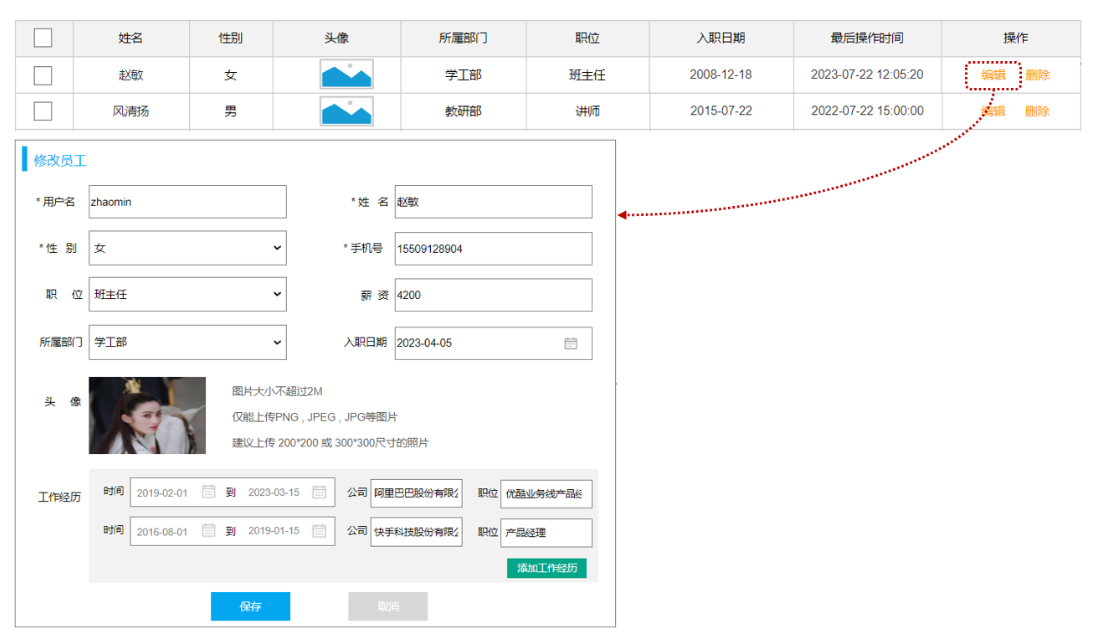

对于修改功能，分为两步实现：

1. 点击 “编辑” 根据ID查询员工的信息，回显展示。

1. 点击 “保存” 按钮，修改员工的信息 。

### 查询回显

> **补充｜回显数据要做适配。** 表单控件的数据结构不一定等于接口结构，例如工作经历的日期范围通常在页面中是 `exprDate: [begin, end]`，提交前再还原为 `begin` 和 `end`。

1). 为 "编辑" 按钮绑定事件

```html
<el-table-column label="操作" align="center">
    <template #default="scope">
      <el-button type="primary" size="small" @click="edit(scope.row.id)"><el-icon><EditPen /></el-icon> 编辑</el-button>
      <el-button type="danger" size="small" @click=""><el-icon><Delete /></el-icon> 删除</el-button>
    </template>
</el-table-column>
```

2). 在 <script> </script> 中定义 edit函数

```javascript
//编辑
const edit = async (id) => {
  const result = await queryInfoApi(id);
  if(result.code){
    dialogVisible.value = true;
    dialogTitle.value = '修改员工';
    employee.value = result.data;

    //对工作经历进行处理
    let exprList = employee.value.exprList;
    if(exprList && exprList.length > 0){
      exprList.forEach((expr) => {
        expr.exprDate = [expr.begin, expr.end];
      })
    }
  }
}
```

这里需要根据id查询员工信息，所以此时要import导入 queryInfoApi。

```javascript
import { queryPageApi, addEmpApi, queryInfoApi } from '@/api/emp'
```

打开浏览器，点击 编辑 按钮，测试数据回显：

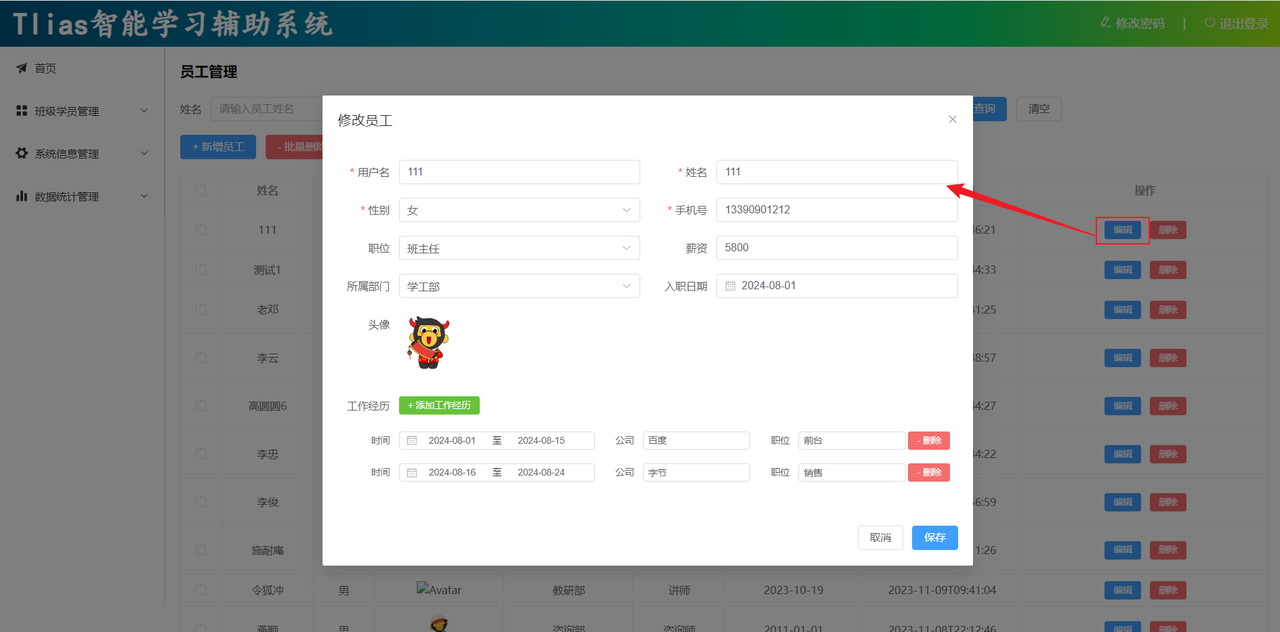

### 修改员工

> **补充｜新增与修改复用。** 同一个 Dialog 可以根据 `employee.id` 判断模式：有 ID 调用更新接口，没有 ID 调用新增接口。打开编辑弹窗时先查询详情，再把后端的 `begin/end` 转换为日期组件需要的数组。

完成了数据回显展示之后，接下来，我们就来完成保存修改操作。 由于修改员工与新增员工共用一个 Dialog对话框。 点击保存按钮时，我们只需要根据 id 来判别是新增员工，还是修改员工。

那我们就需要对保存员工的函数，进行完善优化。 最终代码如下：

```javascript
//保存员工
const save = async () => {
  //表单校验
  if(!empFormRef.value) return;
  empFormRef.value.validate(async (valid) => { //valid 表示是否校验通过: true 通过 / false  不通过
    if(valid){ //通过

      let result;
      if(employee.value.id){ //修改
        result = await updateApi(employee.value);
      }else { //新增
        result = await addApi(employee.value);
      }
      
      if(result.code) {//成功
        ElMessage.success('保存成功');
        dialogVisible.value = false;
        search();
      }else { //失败了
        ElMessage.error(result.msg);
      }
    }else { //不通过
      ElMessage.error('表单校验不通过');
    }
  })
}
```

打开浏览器，测试修改员工信息操作：

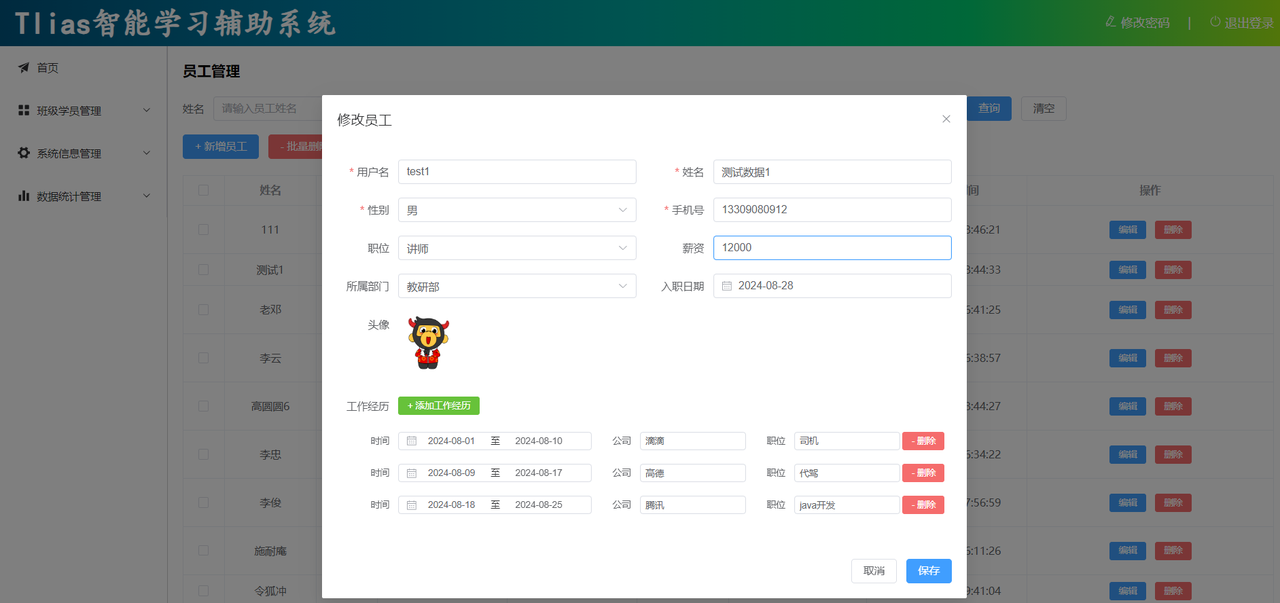

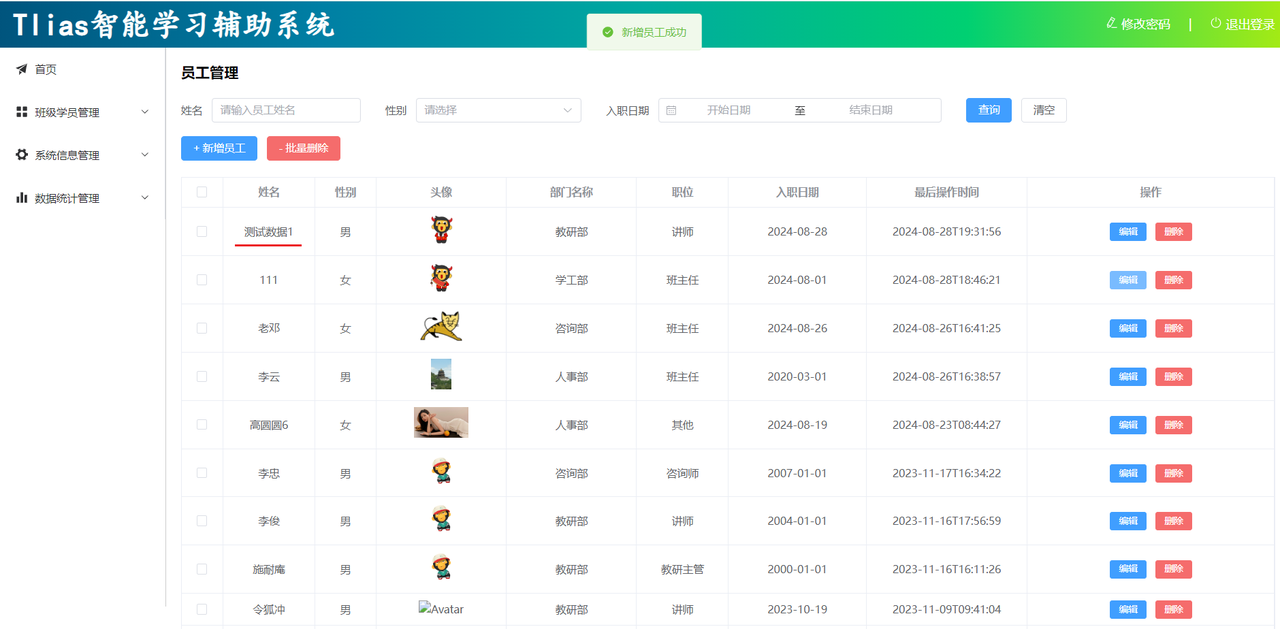

到目前为止，src/views/emp/index.vue 中完整的代码如下：

```html
<script setup>
import { ref, watch, onMounted } from 'vue';
import { queryPageApi, addApi, queryInfoApi, updateApi, deleteApi } from '@/api/emp';
import { queryAllApi as queryAllDeptApi } from '@/api/dept';
import { ElMessage, ElMessageBox } from 'element-plus'

//元数据
//职位列表数据
const jobs = ref([{ name: '班主任', value: 1 },{ name: '讲师', value: 2 },{ name: '学工主管', value: 3 },{ name: '教研主管', value: 4 },{ name: '咨询师', value: 5 },{ name: '其他', value: 6 }])
//性别列表数据
const genders = ref([{ name: '男', value: 1 }, { name: '女', value: 2 }])
//部门列表数据
const depts = ref([])

//搜索表单对象
const searchEmp = ref({name: '', gender: '', date: [], begin: '', end: ''})

//侦听searchEmp的date属性
watch(() => searchEmp.value.date, (newVal, oldVal) => {
  if(newVal.length == 2){
    searchEmp.value.begin = newVal[0];
    searchEmp.value.end = newVal[1];
  }else {
    searchEmp.value.begin = '';
    searchEmp.value.end = '';
  }
})

//钩子函数
onMounted(() => {
  search(); //查询员工列表数据
  queryAllDepts();//查询所有部门列表数据
})

//查询所有部门数据
const queryAllDepts = async () => {
  const result = await queryAllDeptApi();
  if(result.code){
    depts.value = result.data;
  }
}

//查询员工列表
const search = async () => {
  const result = await queryPageApi(searchEmp.value.name, searchEmp.value.gender,
                         searchEmp.value.begin, searchEmp.value.end, currentPage.value, pageSize.value);
  if(result.code){
    empList.value = result.data.rows;
    total.value = result.data.total;
  }
}

//清空
const clear = () => {
  searchEmp.value = {name: '', gender: '', date: [], begin: '', end: ''};
  search();
}

//员工列表数据
const empList = ref([])

//分页
const currentPage = ref(1); //页码
const pageSize = ref(10); //每页展示记录数
const background = ref(true); //背景色
const total = ref(0); //总记录数

//每页展示记录数变化
const handleSizeChange = (val) => {
  search();
}
//页码变化时触发
const handleCurrentChange = (val) => {
  search();
}

//新增员工
const addEmp = () => {
  dialogVisible.value = true;
  dialogTitle.value = '新增员工';
  employee.value = {
    username: '',
    name: '',
    gender: '',
    phone: '',
    job: '',
    salary: '',
    deptId: '',
    entryDate: '',
    image: '',
    exprList: []
  }

  //重置表单的校验规则-提示信息
  if (empFormRef.value){
    empFormRef.value.resetFields();
  }
}

//新增/修改表单
const employee = ref({
  username: '',
  name: '',
  gender: '',
  phone: '',
  job: '',
  salary: '',
  deptId: '',
  entryDate: '',
  image: '',
  exprList: []
})

// 控制弹窗
const dialogVisible = ref(false)
const dialogTitle = ref('新增员工')

// 文件上传
// 图片上传成功后触发
const handleAvatarSuccess = (response) => {
  employee.value.image = response.data;
}
// 文件上传之前触发
const beforeAvatarUpload = (rawFile) => {
  if (rawFile.type !== 'image/jpeg' && rawFile.type !== 'image/png') {
    ElMessage.error('只支持上传图片')
    return false
  } else if (rawFile.size / 1024 / 1024 > 10) {
    ElMessage.error('只能上传10M以内图片')
    return false
  }
  return true
}

//添加工作经历
const addExprItem = () => {
  employee.value.exprList.push({company: '', job: '', begin: '', end: '', exprDate: []});
}
//删除工作经历
const delExprItem = (index) => {
  employee.value.exprList.splice(index,1);
}
//侦听-employee员工对象中的工作经历信息
watch(() => employee.value.exprList, (newVal, oldVal) => {
  if(employee.value.exprList && employee.value.exprList.length > 0){
    employee.value.exprList.forEach((expr) => {
      expr.begin = expr.exprDate[0];
      expr.end = expr.exprDate[1];
    })
  }
}, {deep: true}) //深度侦听

//保存员工
const save = async () => {
  //表单校验
  if(!empFormRef.value) return;
  empFormRef.value.validate(async (valid) => { //valid 表示是否校验通过: true 通过 / false  不通过
    if(valid){ //通过

      let result;
      if(employee.value.id){ //修改
        result = await updateApi(employee.value);
      }else { //新增
        result = await addApi(employee.value);
      }
      
      if(result.code) {//成功
        ElMessage.success('保存成功');
        dialogVisible.value = false;
        search();
      }else { //失败了
        ElMessage.error(result.msg);
      }
    }else { //不通过
      ElMessage.error('表单校验不通过');
    }
  })
}
//表单引用
const empFormRef = ref();

//表单校验规则
const rules = ref({
  username: [
    { required: true, message: '请输入用户名', trigger: 'blur' },
    { min: 2, max: 20, message: '用户名长度应在2到20个字符之间', trigger: 'blur' }
  ],
  name: [
    { required: true, message: '请输入姓名', trigger: 'blur' },
    { min: 2, max: 10, message: '姓名长度应在2到10个字符之间', trigger: 'blur' }
  ],
  gender: [
    { required: true, message: '请选择性别', trigger: 'change' }
  ],
  phone: [
    { required: true, message: '请输入手机号', trigger: 'blur' },
    /**
     * 正则表达式: / ..... / ;  ^ : 以...开始 ;  $ : 以 ... 结束
     * [3-9] : 范围 3-9 之间
     * \d : 数字, [0-9]
     * {9} : 量词
     */
    { pattern: /^1[3-9]\d{9}$/, message: '请输入有效的手机号', trigger: 'blur' }
  ]
});

//编辑
const edit = async (id) => {
  const result = await queryInfoApi(id);
  if(result.code){
    dialogVisible.value = true;
    dialogTitle.value = '修改员工';
    employee.value = result.data;

    //对工作经历进行处理
    let exprList = employee.value.exprList;
    if(exprList && exprList.length > 0){
      exprList.forEach((expr) => {
        expr.exprDate = [expr.begin, expr.end];
      })
    }
  }
}


</script>

<template>
  <h1>员工管理</h1>

  <!-- 搜索栏 -->
  <div class="container">
    <el-form :inline="true" :model="searchEmp" class="demo-form-inline">
      <el-form-item label="姓名">
        <el-input v-model="searchEmp.name" placeholder="请输入员工姓名" />
      </el-form-item>

      <el-form-item label="性别">
        <el-select v-model="searchEmp.gender" placeholder="请选择">
          <el-option label="男" value="1" />
          <el-option label="女" value="2" />
        </el-select>
      </el-form-item>

      <el-form-item label="入职时间">
        <el-date-picker
          v-model="searchEmp.date"
          type="daterange"
          range-separator="到"
          start-placeholder="开始日期"
          end-placeholder="结束日期"
          value-format="YYYY-MM-DD"
        />
      </el-form-item>

      <el-form-item>
        <el-button type="primary" @click="search">查询</el-button>
        <el-button type="info" @click="clear">清空</el-button>
      </el-form-item>
    </el-form>
  </div>
  
  <!-- 功能按钮 -->
  <div class="container">
    <el-button type="primary" @click="addEmp">+ 新增员工</el-button>
    <el-button type="danger" @click="deleteByIds">- 批量删除</el-button>
  </div>

  <!-- 数据展示表格 -->
  <div class="container">
    <el-table :data="empList" border style="width: 100%" @selection-change="handleSelectionChange">
      <el-table-column type="selection" width="55" align="center"/>
      <el-table-column prop="name" label="姓名" width="120" align="center"/>
      <el-table-column label="性别" width="120"  align="center">
        <template #default="scope">
          {{ scope.row.gender == 1 ? '男' : '女' }}
        </template>
      </el-table-column>
      <el-table-column label="头像" width="120"  align="center">
        <template #default="scope">
          <img :src="scope.row.image" height="30px">
        </template>
      </el-table-column>
      <el-table-column prop="deptName" label="所属部门" width="120"  align="center"/>
      <el-table-column prop="job" label="职位" width="120"  align="center">
        <template #default="scope">
          <span v-if="scope.row.job == 1">班主任</span>
          <span v-else-if="scope.row.job == 2">讲师</span>
          <span v-else-if="scope.row.job == 3">学工主管</span>
          <span v-else-if="scope.row.job == 4">教研主管</span>
          <span v-else-if="scope.row.job == 5">咨询师</span>
          <span v-else>其他</span>
        </template>
      </el-table-column>
      <el-table-column prop="entryDate" label="入职日期" width="180"  align="center"/>
      <el-table-column prop="updateTime" label="最后操作时间" width="200"  align="center"/>
      <el-table-column label="操作" align="center">
        <template #default="scope">
          <el-button type="primary" size="small" @click="edit(scope.row.id)"><el-icon><EditPen /></el-icon> 编辑</el-button>
          <el-button type="danger" size="small" @click=""><el-icon><Delete /></el-icon> 删除</el-button>
        </template>
      </el-table-column>
    </el-table>
  </div>

  <!-- 分页条 -->
  <div class="container">
    <el-pagination
      v-model:current-page="currentPage"
      v-model:page-size="pageSize"
      :page-sizes="[5, 10, 20, 30, 50, 75, 100]"
      :background="background"
      layout="total, sizes, prev, pager, next, jumper"
      :total="total"
      @size-change="handleSizeChange"
      @current-change="handleCurrentChange"
    />
  </div>
  
  <!-- 新增员工/修改员工的对话框 -->
  <el-dialog v-model="dialogVisible" :title="dialogTitle">
    <el-form :model="employee" :rules="rules" ref="empFormRef" label-width="80px">
      <!-- 基本信息 -->
      <!-- 第一行 -->
      <el-row :gutter="20">
        <el-col :span="12">
          <el-form-item label="用户名" prop="username">
            <el-input v-model="employee.username" placeholder="请输入员工用户名，2-20个字"></el-input>
          </el-form-item>
        </el-col>
        
        <el-col :span="12">
          <el-form-item label="姓名" prop="name">
            <el-input v-model="employee.name" placeholder="请输入员工姓名，2-10个字"></el-input>
          </el-form-item>
        </el-col>
      </el-row>

      <!-- 第二行 -->
      <el-row :gutter="20">
        <el-col :span="12">
          <el-form-item label="性别"  prop="gender">
            <el-select v-model="employee.gender" placeholder="请选择性别" style="width: 100%;">
              <el-option v-for="g in genders" :key="g.value" :label="g.name" :value="g.value"></el-option>
            </el-select>
          </el-form-item>
        </el-col>

        <el-col :span="12">
          <el-form-item label="手机号" prop="phone">
            <el-input v-model="employee.phone" placeholder="请输入员工手机号"></el-input>
          </el-form-item>
        </el-col>
      </el-row>

      <!-- 第三行 -->
      <el-row :gutter="20">
        <el-col :span="12">
          <el-form-item label="职位">
            <el-select v-model="employee.job" placeholder="请选择职位" style="width: 100%;">
              <el-option v-for="j in jobs" :key="j.value" :label="j.name" :value="j.value"></el-option>
            </el-select>
          </el-form-item>
        </el-col>
        <el-col :span="12">
          <el-form-item label="薪资">
            <el-input v-model="employee.salary" placeholder="请输入员工薪资"></el-input>
          </el-form-item>
        </el-col>
      </el-row>

      <!-- 第四行 -->
      <el-row :gutter="20">
        <el-col :span="12">
          <el-form-item label="所属部门">
            <el-select v-model="employee.deptId" placeholder="请选择部门" style="width: 100%;">
              <el-option v-for="d in depts" :key="d.id" :label="d.name" :value="d.id"></el-option>
            </el-select>
          </el-form-item>
        </el-col>
        <el-col :span="12">
          <el-form-item label="入职日期">
            <el-date-picker v-model="employee.entryDate" type="date" style="width: 100%;" placeholder="选择日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD"></el-date-picker>
          </el-form-item>
        </el-col>
      </el-row>

      <!-- 第五行 -->
      <el-row :gutter="20">
        <el-col :span="24">
          <el-form-item label="头像">
            <el-upload
              class="avatar-uploader"
              action="/api/upload"
              :show-file-list="false"
              :on-success="handleAvatarSuccess"
              :before-upload="beforeAvatarUpload"
              >
              <img v-if="employee.image" :src="employee.image" class="avatar" />
              <el-icon v-else class="avatar-uploader-icon"><Plus /></el-icon>
            </el-upload>
          </el-form-item>
        </el-col>
      </el-row>
      

      <!-- 工作经历 -->
      <!-- 第六行 -->
      <el-row :gutter="10">
        <el-col :span="24">
          <el-form-item label="工作经历">
            <el-button type="success" size="small" @click="addExprItem">+ 添加工作经历</el-button>
          </el-form-item>
        </el-col>
      </el-row>
      
      <!-- 第七行 ...  工作经历 -->
      <el-row :gutter="3" v-for="(expr,index) in employee.exprList">
        <el-col :span="10">
          <el-form-item size="small" label="时间" label-width="80px">
            <el-date-picker type="daterange" v-model="expr.exprDate" range-separator="至" start-placeholder="开始日期" end-placeholder="结束日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD" ></el-date-picker>
          </el-form-item>
        </el-col>

        <el-col :span="6">
          <el-form-item size="small" label="公司" label-width="60px">
            <el-input placeholder="请输入公司名称" v-model="expr.company"></el-input>
          </el-form-item>
        </el-col>

        <el-col :span="6">
          <el-form-item size="small" label="职位" label-width="60px">
            <el-input placeholder="请输入职位" v-model="expr.job"></el-input>
          </el-form-item>
        </el-col>

        <el-col :span="2">
          <el-form-item size="small" label-width="0px">
            <el-button type="danger" @click="delExprItem(index)">- 删除</el-button>
          </el-form-item>
        </el-col>
      </el-row>
    </el-form>
    
    <!-- 底部按钮 -->
    <template #footer>
      <span class="dialog-footer">
        <el-button @click="dialogVisible = false">取消</el-button>
        <el-button type="primary" @click="save">保存</el-button>
      </span>
    </template>
  </el-dialog>

</template>

<style scoped>
.container {
  margin: 10px 0px;
}

.avatar {
  height: 40px;
}
.avatar-uploader .avatar {
  width: 78px;
  height: 78px;
  display: block;
}
.avatar-uploader .el-upload {
  border: 1px dashed var(--el-border-color);
  border-radius: 6px;
  cursor: pointer;
  position: relative;
  overflow: hidden;
  transition: var(--el-transition-duration-fast);
}

.avatar-uploader .el-upload:hover {
  border-color: var(--el-color-primary);
}

.el-icon.avatar-uploader-icon {
  font-size: 28px;
  color: #8c939d;
  width: 78px;
  height: 78px;
  text-align: center;
  border-radius: 10px;
  /* 添加灰色的虚线边框 */
  border: 1px dashed var(--el-border-color);
}
</style>
```

## 删除员工

> **补充｜删除后的分页。** 删除当前页最后一条记录后，若当前页已经超出总页数，应重新计算页码或由后端分页结果决定当前页，避免出现空白页。

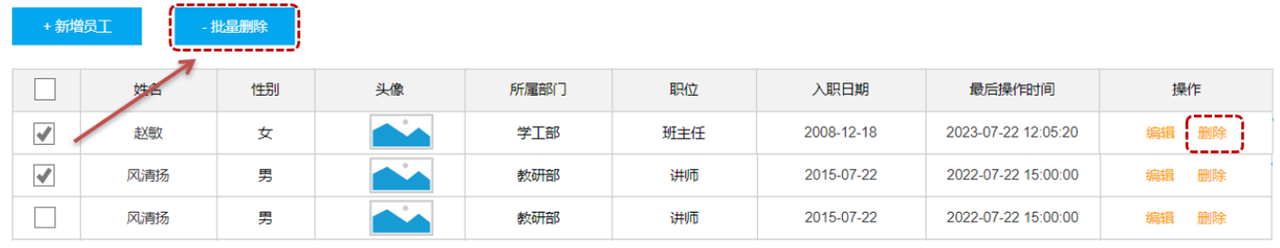

在删除员工信息时，有两个操作入口：

- 点击每条记录之后的“删除”按钮，删除当前这条记录；

- 选择前面的复选框，选中要删除的员工，点击“批量删除”之后，会批量删除员工信息；

### 删除单个

> **补充｜确认和幂等。** 破坏性操作先弹出确认框，请求期间禁用按钮。后端删除接口应按 ID 幂等处理，前端成功后重新查询列表，保证总条数准确。

1). 为 "删除" 按钮  绑定事件

```html
<el-table-column label="操作" fixed="right" align="center">
  <template #default="scope">
    <el-button size="small" type="primary" @click="handleEdit(scope.row.id)">编辑</el-button>
    <el-button size="small" type="danger" @click="deleteById(scope.row.id)">删除</el-button>
  </template>
</el-table-column>
```

2). 在 <script> </script> 中定义函数

```javascript
//删除员工
const deleteById = (id) => {
  //弹出确认框
  ElMessageBox.confirm('您确认删除该员工吗?','提示',
    { confirmButtonText: '确认',cancelButtonText: '取消',type: 'warning'}
  ).then(async () => { //确认
    const result = await deleteApi(id);
    if(result.code){
      ElMessage.success('删除成功');
      search();
    }else{
      ElMessage.error(result.msg);
    }
  }).catch(() => { //取消
    ElMessage.info('您已取消删除');
  })
}
```

这里用到了ElmentPlus中的消息确认框 ElMessageBox，就记得需要引入进来这个组件。

```javascript
import { ElMessage, ElMessageBox } from 'element-plus'
```

打开浏览器，测试一下：

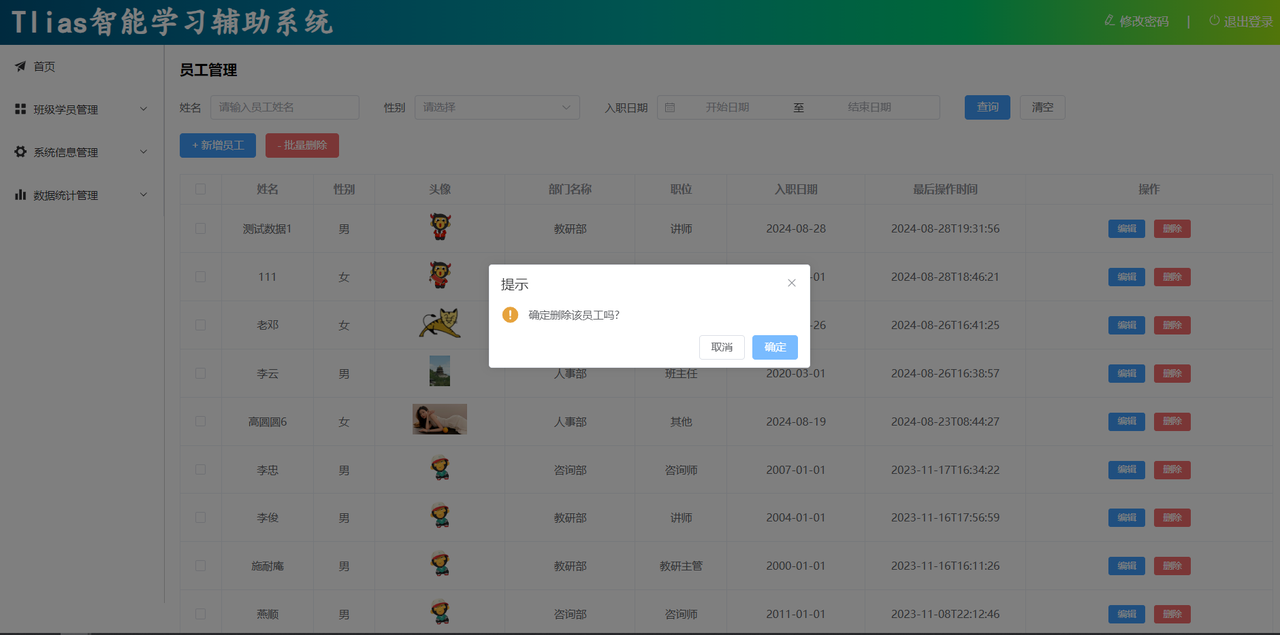

### 批量删除

> **补充｜选择状态。** 用表格的 selection-change 维护选中 ID 数组；提交前检查数组非空，删除成功后清空选择状态并刷新列表。不要只删除前端数组而跳过后端结果。

1). 为复选框绑定事件 @selection-change

```javascript
  <!-- 数据展示表格 -->
  <div class="container">
    <el-table :data="empList" border style="width: 100%" @selection-change="handleSelectionChange">
      <el-table-column type="selection" width="55" align="center"/>
      <el-table-column prop="name" label="姓名" width="120" align="center"/>
      <el-table-column label="性别" width="120"  align="center">
        <template #default="scope">
          {{ scope.row.gender == 1 ? '男' : '女' }}
        </template>
      </el-table-column>
      <el-table-column label="头像" width="120"  align="center">
        <template #default="scope">
          <img :src="scope.row.image" height="30px">
        </template>
      </el-table-column>
      <el-table-column prop="deptName" label="所属部门" width="120"  align="center"/>
      <el-table-column prop="job" label="职位" width="120"  align="center">
        <template #default="scope">
          <span v-if="scope.row.job == 1">班主任</span>
          <span v-else-if="scope.row.job == 2">讲师</span>
          <span v-else-if="scope.row.job == 3">学工主管</span>
          <span v-else-if="scope.row.job == 4">教研主管</span>
          <span v-else-if="scope.row.job == 5">咨询师</span>
          <span v-else>其他</span>
        </template>
      </el-table-column>
      <el-table-column prop="entryDate" label="入职日期" width="180"  align="center"/>
      <el-table-column prop="updateTime" label="最后操作时间" width="200"  align="center"/>
      <el-table-column label="操作" align="center">
        <template #default="scope">
          <el-button type="primary" size="small" @click="edit(scope.row.id)"><el-icon><EditPen /></el-icon> 编辑</el-button>
          <el-button type="danger" size="small" @click="deleteById(scope.row.id)"><el-icon><Delete /></el-icon> 删除</el-button>
        </template>
      </el-table-column>
    </el-table>
  </div>
```

2). 定义 handleSelectionChange 函数

```javascript
//记录勾选的员工的id
const selectedIds = ref([]);
//复选框勾选发生变化时触发 - selection: 当前选中的记录 (数组)
const handleSelectionChange = (selection) => {
  selectedIds.value = selection.map( item => item.id);
}
```

3). 为  "批量删除" 按钮绑定事件

```html
  <el-button type="primary" @click="addEmp"> + 新增员工</el-button>
  <el-button type="danger" @click="deleteByIds"> - 批量删除</el-button>
```

4). 在 <script> </script> 中定义函数

```javascript
//批量删除
const deleteByIds = () => {
  //弹出确认框
  ElMessageBox.confirm('您确认删除该员工吗?','提示',
    { confirmButtonText: '确认',cancelButtonText: '取消',type: 'warning'}
  ).then(async () => { //确认
    if(selectedIds.value && selectedIds.value.length > 0){
      const result = await deleteApi(selectedIds.value);
      if(result.code){
        ElMessage.success('删除成功');
        search();
      }else{
        ElMessage.error(result.msg);
      }
    }else {
      ElMessage.info('您没有选择任何要删除的数据');
    }
  }).catch(() => { //取消
    ElMessage.info('您已取消删除');
  })
}
```

打开浏览器，测试一下：

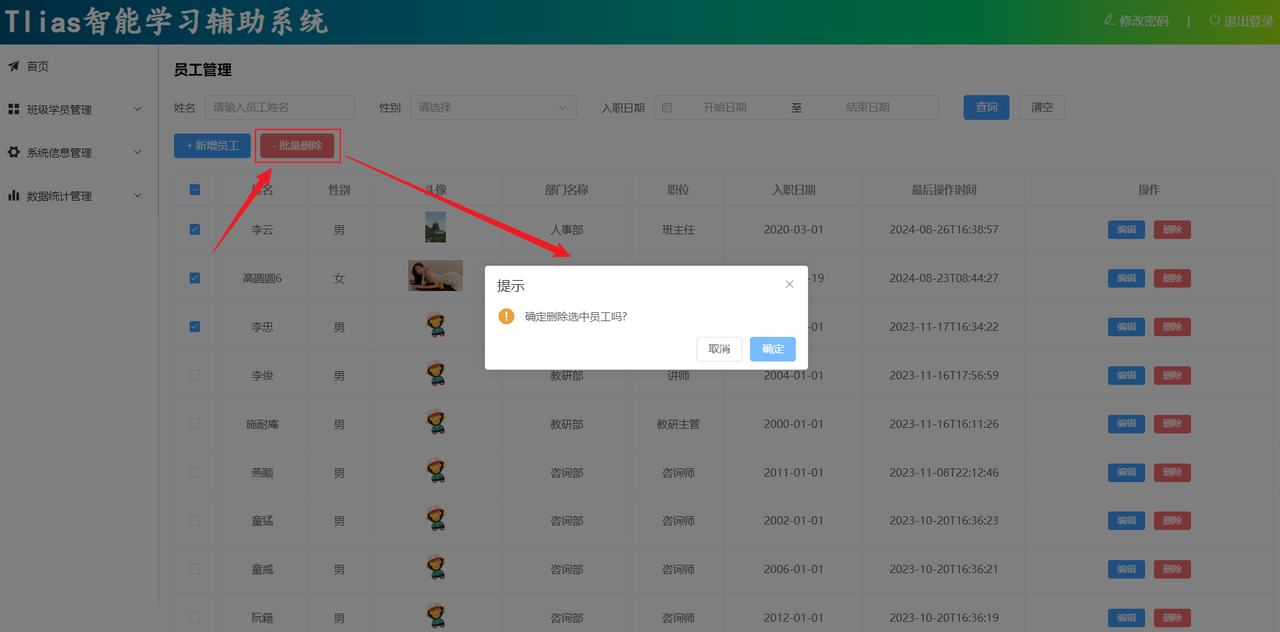

到此呢，关于员工管理的基本的增删改查功能，我们已经完成了。 目前为止，src/views/emp/index.vue 的完整代码如下：

```html
<script setup>
import { ref, watch, onMounted } from 'vue';
import { queryPageApi, addApi, queryInfoApi, updateApi, deleteApi } from '@/api/emp';
import { queryAllApi as queryAllDeptApi } from '@/api/dept';
import { ElMessage, ElMessageBox } from 'element-plus'

//元数据
//职位列表数据
const jobs = ref([{ name: '班主任', value: 1 },{ name: '讲师', value: 2 },{ name: '学工主管', value: 3 },{ name: '教研主管', value: 4 },{ name: '咨询师', value: 5 },{ name: '其他', value: 6 }])
//性别列表数据
const genders = ref([{ name: '男', value: 1 }, { name: '女', value: 2 }])
//部门列表数据
const depts = ref([])

//搜索表单对象
const searchEmp = ref({name: '', gender: '', date: [], begin: '', end: ''})

//侦听searchEmp的date属性
watch(() => searchEmp.value.date, (newVal, oldVal) => {
  if(newVal.length == 2){
    searchEmp.value.begin = newVal[0];
    searchEmp.value.end = newVal[1];
  }else {
    searchEmp.value.begin = '';
    searchEmp.value.end = '';
  }
})

//钩子函数
onMounted(() => {
  search(); //查询员工列表数据
  queryAllDepts();//查询所有部门列表数据
})

//查询所有部门数据
const queryAllDepts = async () => {
  const result = await queryAllDeptApi();
  if(result.code){
    depts.value = result.data;
  }
}

//查询员工列表
const search = async () => {
  const result = await queryPageApi(searchEmp.value.name, searchEmp.value.gender,
                         searchEmp.value.begin, searchEmp.value.end, currentPage.value, pageSize.value);
  if(result.code){
    empList.value = result.data.rows;
    total.value = result.data.total;
  }
}

//清空
const clear = () => {
  searchEmp.value = {name: '', gender: '', date: [], begin: '', end: ''};
  search();
}

//员工列表数据
const empList = ref([])

//分页
const currentPage = ref(1); //页码
const pageSize = ref(10); //每页展示记录数
const background = ref(true); //背景色
const total = ref(0); //总记录数

//每页展示记录数变化
const handleSizeChange = (val) => {
  search();
}
//页码变化时触发
const handleCurrentChange = (val) => {
  search();
}

//新增员工
const addEmp = () => {
  dialogVisible.value = true;
  dialogTitle.value = '新增员工';
  employee.value = {
    username: '',
    name: '',
    gender: '',
    phone: '',
    job: '',
    salary: '',
    deptId: '',
    entryDate: '',
    image: '',
    exprList: []
  }

  //重置表单的校验规则-提示信息
  if (empFormRef.value){
    empFormRef.value.resetFields();
  }
}

//新增/修改表单
const employee = ref({
  username: '',
  name: '',
  gender: '',
  phone: '',
  job: '',
  salary: '',
  deptId: '',
  entryDate: '',
  image: '',
  exprList: []
})

// 控制弹窗
const dialogVisible = ref(false)
const dialogTitle = ref('新增员工')

// 文件上传
// 图片上传成功后触发
const handleAvatarSuccess = (response) => {
  employee.value.image = response.data;
}
// 文件上传之前触发
const beforeAvatarUpload = (rawFile) => {
  if (rawFile.type !== 'image/jpeg' && rawFile.type !== 'image/png') {
    ElMessage.error('只支持上传图片')
    return false
  } else if (rawFile.size / 1024 / 1024 > 10) {
    ElMessage.error('只能上传10M以内图片')
    return false
  }
  return true
}

//添加工作经历
const addExprItem = () => {
  employee.value.exprList.push({company: '', job: '', begin: '', end: '', exprDate: []});
}
//删除工作经历
const delExprItem = (index) => {
  employee.value.exprList.splice(index,1);
}
//侦听-employee员工对象中的工作经历信息
watch(() => employee.value.exprList, (newVal, oldVal) => {
  if(employee.value.exprList && employee.value.exprList.length > 0){
    employee.value.exprList.forEach((expr) => {
      expr.begin = expr.exprDate[0];
      expr.end = expr.exprDate[1];
    })
  }
}, {deep: true}) //深度侦听

//保存员工
const save = async () => {
  //表单校验
  if(!empFormRef.value) return;
  empFormRef.value.validate(async (valid) => { //valid 表示是否校验通过: true 通过 / false  不通过
    if(valid){ //通过

      let result;
      if(employee.value.id){ //修改
        result = await updateApi(employee.value);
      }else { //新增
        result = await addApi(employee.value);
      }
      
      if(result.code) {//成功
        ElMessage.success('保存成功');
        dialogVisible.value = false;
        search();
      }else { //失败了
        ElMessage.error(result.msg);
      }
    }else { //不通过
      ElMessage.error('表单校验不通过');
    }
  })
}
//表单引用
const empFormRef = ref();

//表单校验规则
const rules = ref({
  username: [
    { required: true, message: '请输入用户名', trigger: 'blur' },
    { min: 2, max: 20, message: '用户名长度应在2到20个字符之间', trigger: 'blur' }
  ],
  name: [
    { required: true, message: '请输入姓名', trigger: 'blur' },
    { min: 2, max: 10, message: '姓名长度应在2到10个字符之间', trigger: 'blur' }
  ],
  gender: [
    { required: true, message: '请选择性别', trigger: 'change' }
  ],
  phone: [
    { required: true, message: '请输入手机号', trigger: 'blur' },
    /**
     * 正则表达式: / ..... / ;  ^ : 以...开始 ;  $ : 以 ... 结束
     * [3-9] : 范围 3-9 之间
     * \d : 数字, [0-9]
     * {9} : 量词
     */
    { pattern: /^1[3-9]\d{9}$/, message: '请输入有效的手机号', trigger: 'blur' }
  ]
});

//编辑
const edit = async (id) => {
  const result = await queryInfoApi(id);
  if(result.code){
    dialogVisible.value = true;
    dialogTitle.value = '修改员工';
    employee.value = result.data;

    //对工作经历进行处理
    let exprList = employee.value.exprList;
    if(exprList && exprList.length > 0){
      exprList.forEach((expr) => {
        expr.exprDate = [expr.begin, expr.end];
      })
    }
  }
}

//删除员工
const deleteById = (id) => {
  //弹出确认框
  ElMessageBox.confirm('您确认删除该员工吗?','提示',
    { confirmButtonText: '确认',cancelButtonText: '取消',type: 'warning'}
  ).then(async () => { //确认
    const result = await deleteApi(id);
    if(result.code){
      ElMessage.success('删除成功');
      search();
    }else{
      ElMessage.error(result.msg);
    }
  }).catch(() => { //取消
    ElMessage.info('您已取消删除');
  })
}
//记录勾选的员工的id
const selectedIds = ref([]);
//复选框勾选发生变化时触发 - selection: 当前选中的记录 (数组)
const handleSelectionChange = (selection) => {
  selectedIds.value = selection.map( item => item.id);
}

//批量删除
const deleteByIds = () => {
  //弹出确认框
  ElMessageBox.confirm('您确认删除该员工吗?','提示',
    { confirmButtonText: '确认',cancelButtonText: '取消',type: 'warning'}
  ).then(async () => { //确认
    if(selectedIds.value && selectedIds.value.length > 0){
      const result = await deleteApi(selectedIds.value);
      if(result.code){
        ElMessage.success('删除成功');
        search();
      }else{
        ElMessage.error(result.msg);
      }
    }else {
      ElMessage.info('您没有选择任何要删除的数据');
    }
  }).catch(() => { //取消
    ElMessage.info('您已取消删除');
  })
}

</script>

<template>
  <h1>员工管理</h1>

  <!-- 搜索栏 -->
  <div class="container">
    <el-form :inline="true" :model="searchEmp" class="demo-form-inline">
      <el-form-item label="姓名">
        <el-input v-model="searchEmp.name" placeholder="请输入员工姓名" />
      </el-form-item>

      <el-form-item label="性别">
        <el-select v-model="searchEmp.gender" placeholder="请选择">
          <el-option label="男" value="1" />
          <el-option label="女" value="2" />
        </el-select>
      </el-form-item>

      <el-form-item label="入职时间">
        <el-date-picker
          v-model="searchEmp.date"
          type="daterange"
          range-separator="到"
          start-placeholder="开始日期"
          end-placeholder="结束日期"
          value-format="YYYY-MM-DD"
        />
      </el-form-item>

      <el-form-item>
        <el-button type="primary" @click="search">查询</el-button>
        <el-button type="info" @click="clear">清空</el-button>
      </el-form-item>
    </el-form>
  </div>
  
  <!-- 功能按钮 -->
  <div class="container">
    <el-button type="primary" @click="addEmp">+ 新增员工</el-button>
    <el-button type="danger" @click="deleteByIds">- 批量删除</el-button>
  </div>

  <!-- 数据展示表格 -->
  <div class="container">
    <el-table :data="empList" border style="width: 100%" @selection-change="handleSelectionChange">
      <el-table-column type="selection" width="55" align="center"/>
      <el-table-column prop="name" label="姓名" width="120" align="center"/>
      <el-table-column label="性别" width="120"  align="center">
        <template #default="scope">
          {{ scope.row.gender == 1 ? '男' : '女' }}
        </template>
      </el-table-column>
      <el-table-column label="头像" width="120"  align="center">
        <template #default="scope">
          <img :src="scope.row.image" height="30px">
        </template>
      </el-table-column>
      <el-table-column prop="deptName" label="所属部门" width="120"  align="center"/>
      <el-table-column prop="job" label="职位" width="120"  align="center">
        <template #default="scope">
          <span v-if="scope.row.job == 1">班主任</span>
          <span v-else-if="scope.row.job == 2">讲师</span>
          <span v-else-if="scope.row.job == 3">学工主管</span>
          <span v-else-if="scope.row.job == 4">教研主管</span>
          <span v-else-if="scope.row.job == 5">咨询师</span>
          <span v-else>其他</span>
        </template>
      </el-table-column>
      <el-table-column prop="entryDate" label="入职日期" width="180"  align="center"/>
      <el-table-column prop="updateTime" label="最后操作时间" width="200"  align="center"/>
      <el-table-column label="操作" align="center">
        <template #default="scope">
          <el-button type="primary" size="small" @click="edit(scope.row.id)"><el-icon><EditPen /></el-icon> 编辑</el-button>
          <el-button type="danger" size="small" @click="deleteById(scope.row.id)"><el-icon><Delete /></el-icon> 删除</el-button>
        </template>
      </el-table-column>
    </el-table>
  </div>

  <!-- 分页条 -->
  <div class="container">
    <el-pagination
      v-model:current-page="currentPage"
      v-model:page-size="pageSize"
      :page-sizes="[5, 10, 20, 30, 50, 75, 100]"
      :background="background"
      layout="total, sizes, prev, pager, next, jumper"
      :total="total"
      @size-change="handleSizeChange"
      @current-change="handleCurrentChange"
    />
  </div>
  
  <!-- 新增员工/修改员工的对话框 -->
  <el-dialog v-model="dialogVisible" :title="dialogTitle">
    <el-form :model="employee" :rules="rules" ref="empFormRef" label-width="80px">
      <!-- 基本信息 -->
      <!-- 第一行 -->
      <el-row :gutter="20">
        <el-col :span="12">
          <el-form-item label="用户名" prop="username">
            <el-input v-model="employee.username" placeholder="请输入员工用户名，2-20个字"></el-input>
          </el-form-item>
        </el-col>
        
        <el-col :span="12">
          <el-form-item label="姓名" prop="name">
            <el-input v-model="employee.name" placeholder="请输入员工姓名，2-10个字"></el-input>
          </el-form-item>
        </el-col>
      </el-row>

      <!-- 第二行 -->
      <el-row :gutter="20">
        <el-col :span="12">
          <el-form-item label="性别"  prop="gender">
            <el-select v-model="employee.gender" placeholder="请选择性别" style="width: 100%;">
              <el-option v-for="g in genders" :key="g.value" :label="g.name" :value="g.value"></el-option>
            </el-select>
          </el-form-item>
        </el-col>

        <el-col :span="12">
          <el-form-item label="手机号" prop="phone">
            <el-input v-model="employee.phone" placeholder="请输入员工手机号"></el-input>
          </el-form-item>
        </el-col>
      </el-row>

      <!-- 第三行 -->
      <el-row :gutter="20">
        <el-col :span="12">
          <el-form-item label="职位">
            <el-select v-model="employee.job" placeholder="请选择职位" style="width: 100%;">
              <el-option v-for="j in jobs" :key="j.value" :label="j.name" :value="j.value"></el-option>
            </el-select>
          </el-form-item>
        </el-col>
        <el-col :span="12">
          <el-form-item label="薪资">
            <el-input v-model="employee.salary" placeholder="请输入员工薪资"></el-input>
          </el-form-item>
        </el-col>
      </el-row>

      <!-- 第四行 -->
      <el-row :gutter="20">
        <el-col :span="12">
          <el-form-item label="所属部门">
            <el-select v-model="employee.deptId" placeholder="请选择部门" style="width: 100%;">
              <el-option v-for="d in depts" :key="d.id" :label="d.name" :value="d.id"></el-option>
            </el-select>
          </el-form-item>
        </el-col>
        <el-col :span="12">
          <el-form-item label="入职日期">
            <el-date-picker v-model="employee.entryDate" type="date" style="width: 100%;" placeholder="选择日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD"></el-date-picker>
          </el-form-item>
        </el-col>
      </el-row>

      <!-- 第五行 -->
      <el-row :gutter="20">
        <el-col :span="24">
          <el-form-item label="头像">
            <el-upload
              class="avatar-uploader"
              action="/api/upload"
              :show-file-list="false"
              :on-success="handleAvatarSuccess"
              :before-upload="beforeAvatarUpload"
              >
              <img v-if="employee.image" :src="employee.image" class="avatar" />
              <el-icon v-else class="avatar-uploader-icon"><Plus /></el-icon>
            </el-upload>
          </el-form-item>
        </el-col>
      </el-row>
      

      <!-- 工作经历 -->
      <!-- 第六行 -->
      <el-row :gutter="10">
        <el-col :span="24">
          <el-form-item label="工作经历">
            <el-button type="success" size="small" @click="addExprItem">+ 添加工作经历</el-button>
          </el-form-item>
        </el-col>
      </el-row>
      
      <!-- 第七行 ...  工作经历 -->
      <el-row :gutter="3" v-for="(expr,index) in employee.exprList">
        <el-col :span="10">
          <el-form-item size="small" label="时间" label-width="80px">
            <el-date-picker type="daterange" v-model="expr.exprDate" range-separator="至" start-placeholder="开始日期" end-placeholder="结束日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD" ></el-date-picker>
          </el-form-item>
        </el-col>

        <el-col :span="6">
          <el-form-item size="small" label="公司" label-width="60px">
            <el-input placeholder="请输入公司名称" v-model="expr.company"></el-input>
          </el-form-item>
        </el-col>

        <el-col :span="6">
          <el-form-item size="small" label="职位" label-width="60px">
            <el-input placeholder="请输入职位" v-model="expr.job"></el-input>
          </el-form-item>
        </el-col>

        <el-col :span="2">
          <el-form-item size="small" label-width="0px">
            <el-button type="danger" @click="delExprItem(index)">- 删除</el-button>
          </el-form-item>
        </el-col>
      </el-row>
    </el-form>
    
    <!-- 底部按钮 -->
    <template #footer>
      <span class="dialog-footer">
        <el-button @click="dialogVisible = false">取消</el-button>
        <el-button type="primary" @click="save">保存</el-button>
      </span>
    </template>
  </el-dialog>

</template>

<style scoped>
.container {
  margin: 10px 0px;
}

.avatar {
  height: 40px;
}
.avatar-uploader .avatar {
  width: 78px;
  height: 78px;
  display: block;
}
.avatar-uploader .el-upload {
  border: 1px dashed var(--el-border-color);
  border-radius: 6px;
  cursor: pointer;
  position: relative;
  overflow: hidden;
  transition: var(--el-transition-duration-fast);
}

.avatar-uploader .el-upload:hover {
  border-color: var(--el-color-primary);
}

.el-icon.avatar-uploader-icon {
  font-size: 28px;
  color: #8c939d;
  width: 78px;
  height: 78px;
  text-align: center;
  border-radius: 10px;
  /* 添加灰色的虚线边框 */
  border: 1px dashed var(--el-border-color);
}
</style>
```

## 登录退出

> **补充｜会话边界。** 登录状态至少包括 token、当前用户和路由状态。退出时同时清理本地存储和内存状态，避免刷新后仍能访问需要鉴权的页面。

员工的增删改查功能我们完成之后，最后我们再来完成一个功能，那就是登录退出功能。

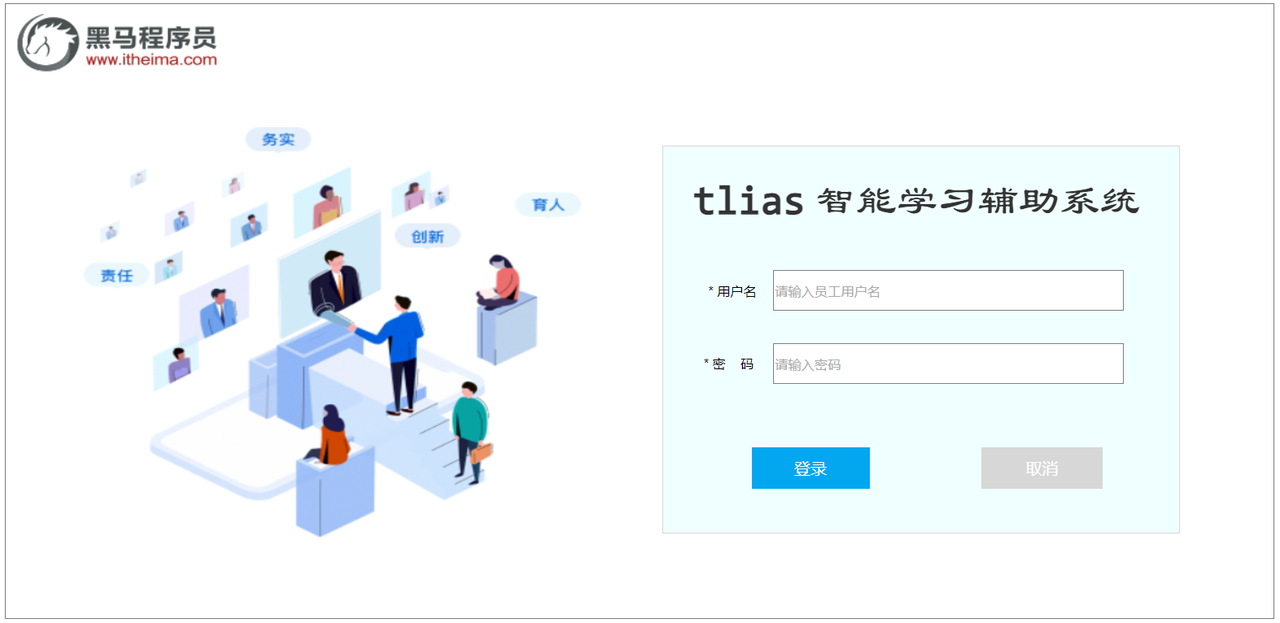

登录页面所在位置为：src/views/login/index.vue，基本的页面布局，我们已经写好了。

我们可以在浏览器中访问路径：http://localhost:5173/login 访问到登录页面。

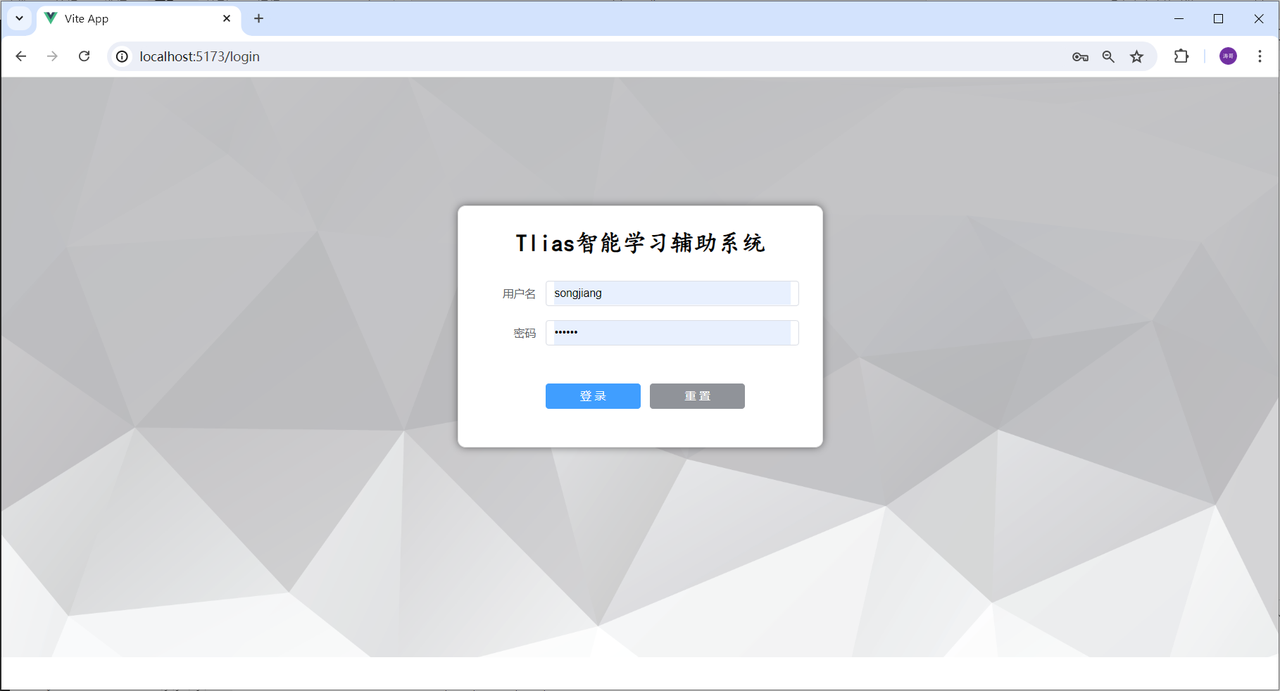

那接下来呢，我们就先来完成登录功能。

### 登录

> **补充｜错误处理。** 登录请求失败时保留表单输入并展示后端消息；成功后只保存必要的 token 信息，再跳转到系统首页或用户原本要访问的页面。

1). 定义登录请求的api : src/api/login.js

```javascript
import request from '@/utils/request'

//登录
export const loginApi = (data) => request.post('/login', data)
```

2). 在 src/views/login/index.vue 中增加如下代码:

```html
<script setup>
import { ref } from 'vue'
import {loginApi} from '@/api/login'
import { ElMessage } from 'element-plus'
import { useRouter } from 'vue-router'

let loginForm = ref({username:'', password:''})
let router = useRouter()

//登录
const login = async () => {
  const result = await loginApi(loginForm.value)
  if (result.code) {// 登录成功
    ElMessage.success('登录成功')
    localStorage.setItem('loginUser', JSON.stringify(result.data))
    router.push('/')// 跳转
  }else {
    ElMessage.error(result.msg)
  }
}

//取消
const clear = () => {
  loginForm.value = {
    username: '',
    password: ''
  }
}
</script>

<template>
  <div id="container">
    <div class="login-form">
      <el-form label-width="80px">
        <p class="title">Tlias智能学习辅助系统</p>
        <el-form-item label="用户名" prop="username">
          <el-input v-model="loginForm.username" placeholder="请输入用户名"></el-input>
        </el-form-item>
        
        <el-form-item label="密码" prop="password">
          <el-input type="password" v-model="loginForm.password" placeholder="请输入密码"></el-input>
        </el-form-item>

        <el-form-item>
          <el-button class="button" type="primary" @click="login">登 录</el-button>
          <el-button class="button" type="info" @click="clear">重 置</el-button>
        </el-form-item>
      </el-form>
    </div>
  </div>
</template>

<style scoped>
#container {
  padding: 10%;
  height: 410px;
  background-image: url('../../assets/bg1.jpg');
  background-repeat: no-repeat;
  background-size: cover;
}

.login-form {
  max-width: 400px;
  padding: 30px;
  margin: 0 auto;
  border: 1px solid #e0e0e0;
  border-radius: 10px;
  box-shadow: 0 0 10px rgba(0, 0, 0, 0.5);
  background-color: white;
}

.title {
  font-size: 30px;
  font-family: '楷体';
  text-align: center;
  margin-bottom: 30px;
  font-weight: bold;
}

.button {
  margin-top: 30px;
  width: 120px;
}
</style>
```

在登录成功之后，需要记录用户的登录信息，这里我们可以直接将用户的登录信息记录在浏览器端的 localStorage 本地存储中，以后需要使用登录的相关信息，直接从 localStorage 中取出即可。

**讲义提示**

> - localStorage是浏览器提供的本地存储机制 (5MB)。

> - 存储形式为key-value形式，键和值都是字符串类型。

> - API方法：

> - localStorage.setItem(key, value)

> - localStorage.getItem(key)

> - localStorage.removeItem(key)

> - localStorage.clear()

### 携带令牌访问

> **补充｜请求拦截器。** 在 Axios 请求拦截器中统一读取 token 并设置 `Authorization` 请求头，避免每个 API 方法重复拼接鉴权逻辑。具体前缀要与后端约定一致，例如 `Bearer <token>`。

在后续的每一次Ajax请求中都获取 localStorage 中的令牌，在请求头中将令牌携带到服务端。 如果这么做，就会非常麻烦，需要在每一次ajax请求的时候获取中存储在 localStorage 中的令牌，并携带到服务端，是非常繁琐的。

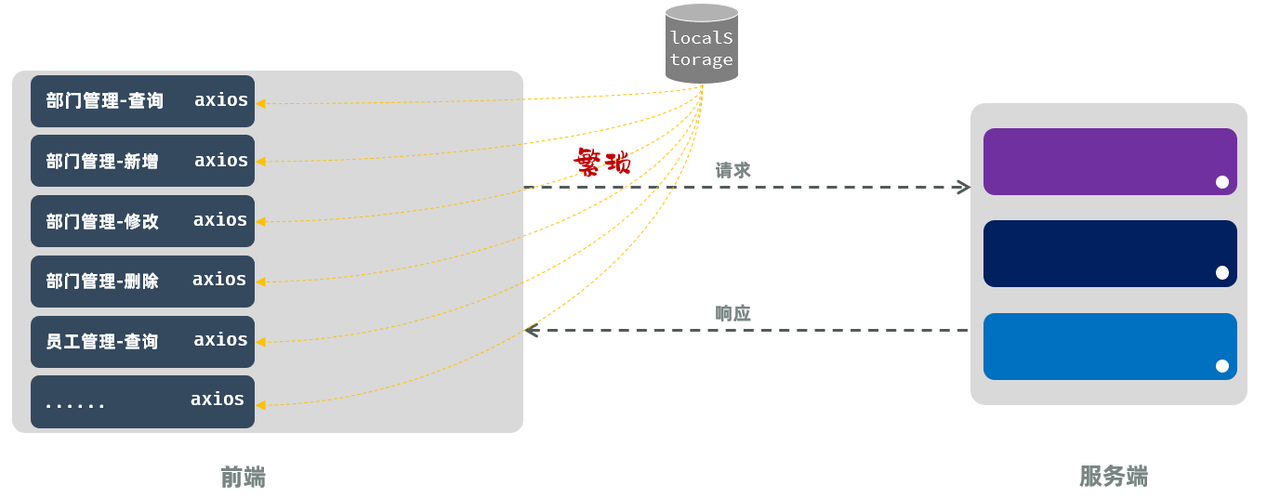

我们可以思考一下，目前我们项目的Ajax请求，是不是都是基于Axios发送的，而在我们的项目中，我们是自己定义了一个axios的请求对象request。所有的异步请求，是不都是基于request对象发起的。 所以，这里呢，我们可以借助于axios中提供的拦截器来进行统一处理。

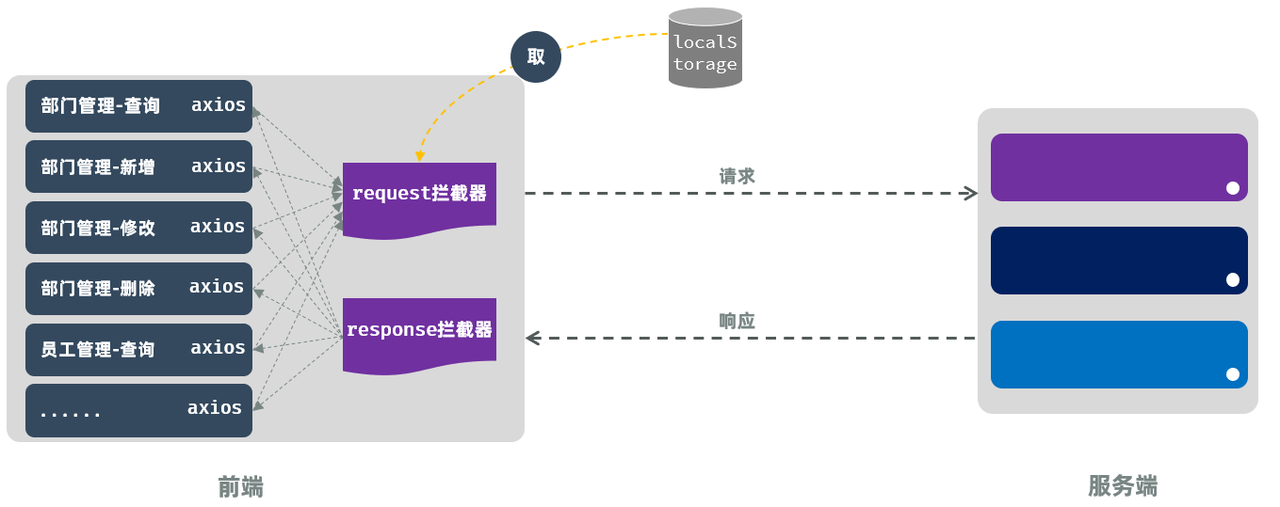

接下来，我们就需要在request.js 中通过axios的拦截器实现此功能。具体代码实现如下:

```javascript
import axios from 'axios'

//创建axios实例对象
const request = axios.create({
  baseURL: '/api',
  timeout: 600000
})

//axios的请求 request 拦截器, 每次请求获取localStorage中的loginUser, 从中获取到token, 在请求头token中携带到服务端
request.interceptors.request.use(
  (config) => {
    let loginUser = JSON.parse(localStorage.getItem('loginUser'))
    console.log(localStorage.getItem('loginUser'))
    if (loginUser) {
      config.headers.token = loginUser.token
    }
    return config
  }
)

//axios的响应 response 拦截器
request.interceptors.response.use(
  (response) => { //成功回调
    return response.data
  },
  (error) => { //失败回调
    return Promise.reject(error)
  }
)

export default request
```

### 响应401跳转到登录页面

> **补充｜避免跳转循环。** 响应拦截器遇到 401 时清理 token，再跳转登录页；登录接口本身和登录页资源请求应避免重复触发同一套跳转逻辑。

目前，即使用户未登录的情况下访问服务器，服务器会响应401状态码，但是前端并不会跳转到登录页面。 因为，我们在前端并未做任何的拦截判断。接下来，我们就来实现此功能，我们只需要在服务端将数据响应给前端时，在axios的响应拦截器中统一判断处理即可。

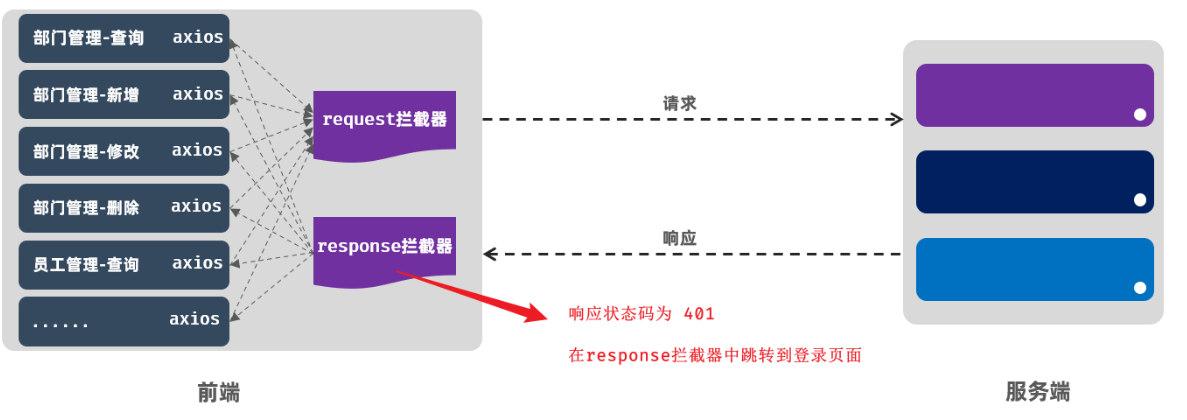

接下来，我们就需要在request.js 中通过axios的响应拦截器实现此功能。具体代码如下：

```javascript
import axios from 'axios'
import { ElMessage } from 'element-plus'
import router from '../router'

//创建axios实例对象
const request = axios.create({
  baseURL: '/api',
  timeout: 600000
})

//axios的请求 request 拦截器, 每次请求获取localStorage中的loginUser, 从中获取到token, 在请求头token中携带到服务端
request.interceptors.request.use(
  (config) => {
    let loginUser = JSON.parse(localStorage.getItem('loginUser'))
    console.log(localStorage.getItem('loginUser'))
    if (loginUser) {
      config.headers.token = loginUser.token
    }
    return config
  }
)

//axios的响应 response 拦截器
request.interceptors.response.use(
  (response) => { //成功回调
    return response.data
  },
  (error) => { //失败回调
    //如果响应的状态码为401, 则路由到登录页面
    if (error.response.status === 401) {
      ElMessage.error('登录失效, 请重新登录')
      router.push('/login')
    }else{
      ElMessage.success('接口访问异常')
    }
    return Promise.reject(error)
  }
)

export default request
```

### 展示登录用户

> **补充｜来源可信。** 从后端查询当前用户并展示头像、姓名等信息，不要仅依赖客户端可修改的显示字段。用户信息加载失败时提供默认头像和可读提示。

```html
<script setup>
import {ref, onMounted} from 'vue'
const loginName = ref('')
//定义钩子函数, 获取登录用户名
onMounted(() => {
  //获取登录用户名
  let loginUser = JSON.parse(localStorage.getItem('loginUser'))
  if (loginUser) {
    loginName.value = loginUser.name
  }
})
</script>

<template>
  <div class="common-layout">
    <el-container>
      <!-- Header 区域 -->
      <el-header class="header">
        <span class="title">Tlias智能学习辅助系统</span>
        <span class="right_tool">
          <a href="">
            <el-icon><EditPen /></el-icon> 修改密码 &nbsp;&nbsp;&nbsp; |  &nbsp;&nbsp;&nbsp;
          </a>
          <a href="">
            <el-icon><SwitchButton /></el-icon> 退出登录 【{{ loginName }}】
          </a>
        </span>
      </el-header>
      
      <el-container>
        <!-- 左侧菜单 -->
        <el-aside width="200px" class="aside">

          <el-menu router>
            <!-- 首页菜单 -->
            <el-menu-item index="/index">
              <el-icon><Promotion /></el-icon> 首页
            </el-menu-item>
            
            <!-- 班级管理菜单 -->
            <el-sub-menu index="/manage">
              <template #title>
                <el-icon><Menu /></el-icon> 班级学员管理
              </template>
              <el-menu-item index="/clazz">
                <el-icon><HomeFilled /></el-icon>班级管理
              </el-menu-item>
              <el-menu-item index="/stu">
                <el-icon><UserFilled /></el-icon>学员管理
              </el-menu-item>
            </el-sub-menu>
            
            <!-- 系统信息管理 -->
            <el-sub-menu index="/system">
              <template #title>
                <el-icon><Tools /></el-icon>系统信息管理
              </template>
              <el-menu-item index="/dept">
                <el-icon><HelpFilled /></el-icon>部门管理
              </el-menu-item>
              <el-menu-item index="/emp">
                <el-icon><Avatar /></el-icon>员工管理
              </el-menu-item>
            </el-sub-menu>

            <!-- 数据统计管理 -->
            <el-sub-menu index="/report">
              <template #title>
                <el-icon><Histogram /></el-icon>数据统计管理
              </template>
              <el-menu-item index="/report/emp">
                <el-icon><InfoFilled /></el-icon>员工信息统计
              </el-menu-item>
              <el-menu-item index="/report/stu">
                <el-icon><Share /></el-icon>学员信息统计
              </el-menu-item>
              <el-menu-item index="/log">
                <el-icon><Document /></el-icon>日志信息统计
              </el-menu-item>
            </el-sub-menu>
          </el-menu>
        </el-aside>
        
        <!-- 主展示区域 -->
        <el-main>
          <router-view></router-view>
        </el-main>
      </el-container>
    </el-container>
  </div>
</template>

<style scoped>
.header {
  background-image: linear-gradient(to right, #00547d, #007fa4, #00aaa0, #00d072, #a8eb12);
}

.title {
  color: white;
  font-size: 40px;
  font-family: 楷体;
  line-height: 60px;
  font-weight: bolder;
}

.right_tool{
  float: right;
  line-height: 60px;
}

a {
  color: white;
  text-decoration: none;
}

.aside {
  width: 220px;
  border-right: 1px solid #ccc;
  height: 730px;
}
</style>
```

我们打开浏览器，完成登录之后，就可以看到，在退出登录之后，就显示出了当前登录员工的姓名。效果如下：

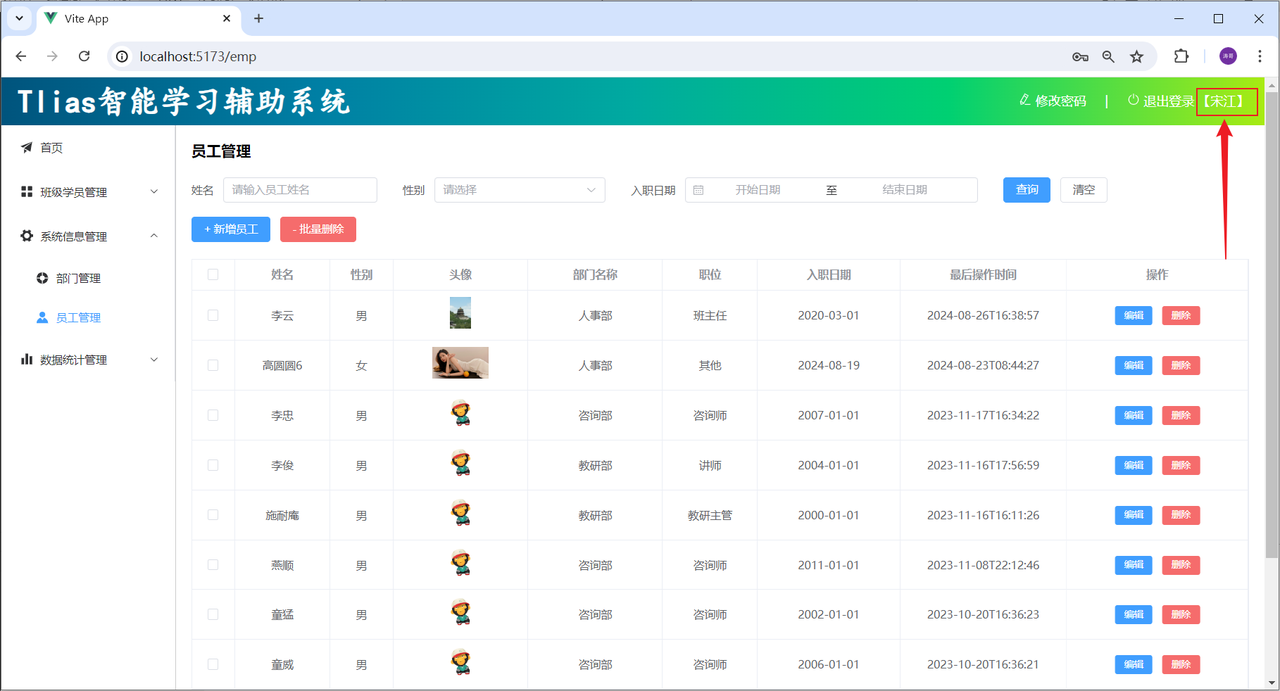

### 退出

> **补充｜退出后回收状态。** 退出成功或接口异常都应清除本地 token，并回到登录页；必要时重置 Pinia/Vue 响应式状态，防止上一个用户的信息残留。

```html
<script setup>
import {ref, onMounted} from 'vue'
import { ElMessage, ElMessageBox } from 'element-plus';
import {useRouter} from 'vue-router'

let router = useRouter()

const loginName = ref('')
//定义钩子函数, 获取登录用户名
onMounted(() => {
  //获取登录用户名
  let loginUser = JSON.parse(localStorage.getItem('loginUser'))
  if (loginUser) {
    loginName.value = loginUser.name
  }
})

const logout = () => {
  //弹出确认框, 如果确认, 则退出登录, 跳转到登录页面
  ElMessageBox.confirm('确认退出登录吗?', '提示', {
    confirmButtonText: '确定',
    cancelButtonText: '取消',
    type: 'warning'
  }).then(() => {//确认, 则清空登录信息
    ElMessage.success('退出登录成功')
    localStorage.removeItem('loginUser')
    router.push('/login')//跳转到登录页面
  })
}
</script>

<template>
  <div class="common-layout">
    <el-container>
      <!-- Header 区域 -->
      <el-header class="header">
        <span class="title">Tlias智能学习辅助系统</span>
        <span class="right_tool">
          <a href="">
            <el-icon><EditPen /></el-icon> 修改密码 &nbsp;&nbsp;&nbsp; |  &nbsp;&nbsp;&nbsp;
          </a>
          <a href="javascript:void(0)" @click="logout">
            <el-icon><SwitchButton /></el-icon> 退出登录 【{{ loginName }}】
          </a>
        </span>
      </el-header>
      
      <el-container>
        <!-- 左侧菜单 -->
        <el-aside width="200px" class="aside">

          <el-menu router>
            <!-- 首页菜单 -->
            <el-menu-item index="/index">
              <el-icon><Promotion /></el-icon> 首页
            </el-menu-item>
            
            <!-- 班级管理菜单 -->
            <el-sub-menu index="/manage">
              <template #title>
                <el-icon><Menu /></el-icon> 班级学员管理
              </template>
              <el-menu-item index="/clazz">
                <el-icon><HomeFilled /></el-icon>班级管理
              </el-menu-item>
              <el-menu-item index="/stu">
                <el-icon><UserFilled /></el-icon>学员管理
              </el-menu-item>
            </el-sub-menu>
            
            <!-- 系统信息管理 -->
            <el-sub-menu index="/system">
              <template #title>
                <el-icon><Tools /></el-icon>系统信息管理
              </template>
              <el-menu-item index="/dept">
                <el-icon><HelpFilled /></el-icon>部门管理
              </el-menu-item>
              <el-menu-item index="/emp">
                <el-icon><Avatar /></el-icon>员工管理
              </el-menu-item>
            </el-sub-menu>

            <!-- 数据统计管理 -->
            <el-sub-menu index="/report">
              <template #title>
                <el-icon><Histogram /></el-icon>数据统计管理
              </template>
              <el-menu-item index="/report/emp">
                <el-icon><InfoFilled /></el-icon>员工信息统计
              </el-menu-item>
              <el-menu-item index="/report/stu">
                <el-icon><Share /></el-icon>学员信息统计
              </el-menu-item>
              <el-menu-item index="/log">
                <el-icon><Document /></el-icon>日志信息统计
              </el-menu-item>
            </el-sub-menu>
          </el-menu>
        </el-aside>
        
        <!-- 主展示区域 -->
        <el-main>
          <router-view></router-view>
        </el-main>
      </el-container>
    </el-container>
  </div>
</template>

<style scoped>
.header {
  background-image: linear-gradient(to right, #00547d, #007fa4, #00aaa0, #00d072, #a8eb12);
}

.title {
  color: white;
  font-size: 40px;
  font-family: 楷体;
  line-height: 60px;
  font-weight: bolder;
}

.right_tool{
  float: right;
  line-height: 60px;
}

a {
  color: white;
  text-decoration: none;
}

.aside {
  width: 220px;
  border-right: 1px solid #ccc;
  height: 730px;
}
</style>
```

我们打开浏览器，完成登录之后，就可以看到，在退出登录之后，就显示出了当前登录员工的姓名。然后点击退出登录，就可以看到效果如下：

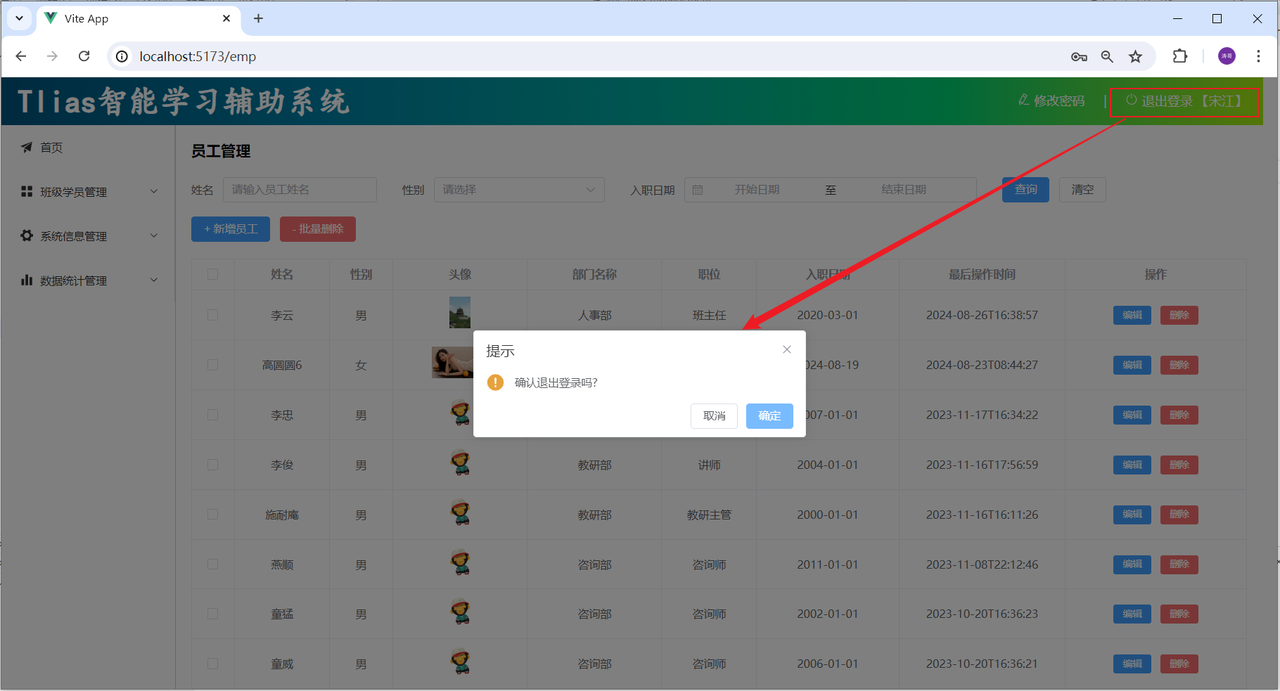

点击确定之后，就会退出登录，跳转到登录页面。

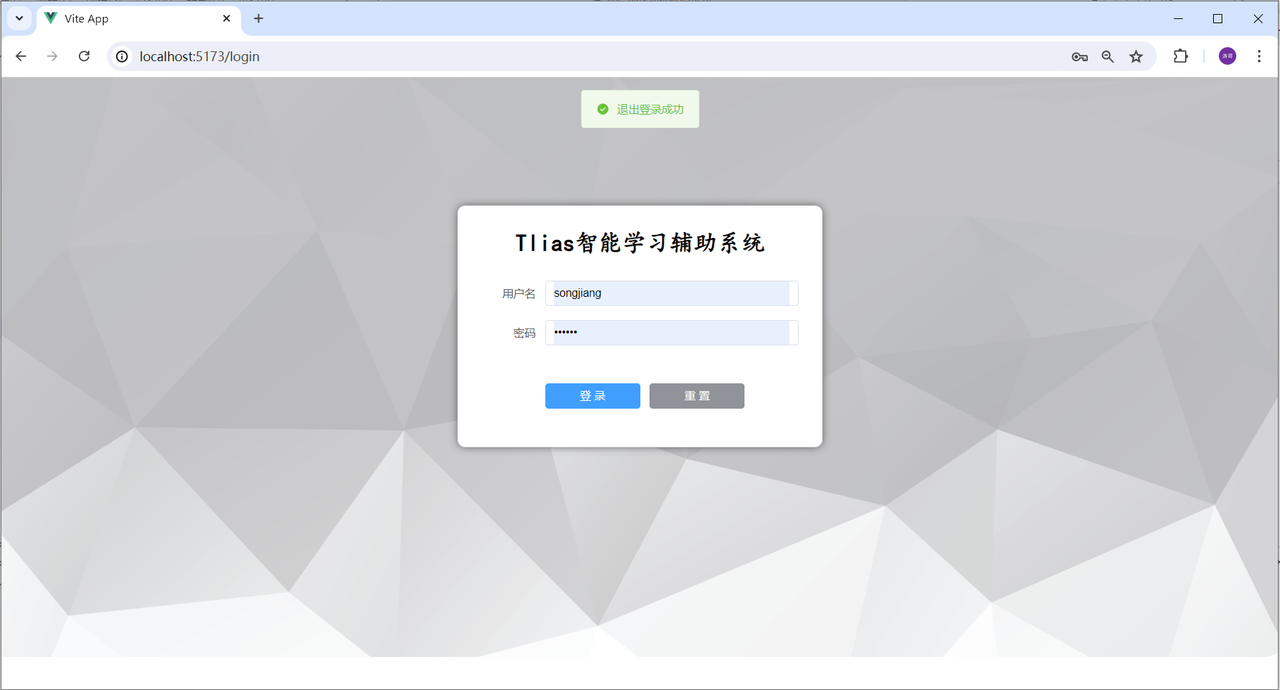

### 图片上传401问题

> **补充｜上传是独立请求。** `el-upload` 的 `action` 请求不会自动复用 Axios 拦截器，需要通过 `headers` 或自定义 `http-request` 显式带上 token，并处理 401、文件类型和大小限制。

目前，我们已经完成了部门管理，员工管理，以及登录退出等所有的功能。 但是其实目前程序中还存在一点小问题，那就是图片上传的时候，服务器端响应 401。如下图：

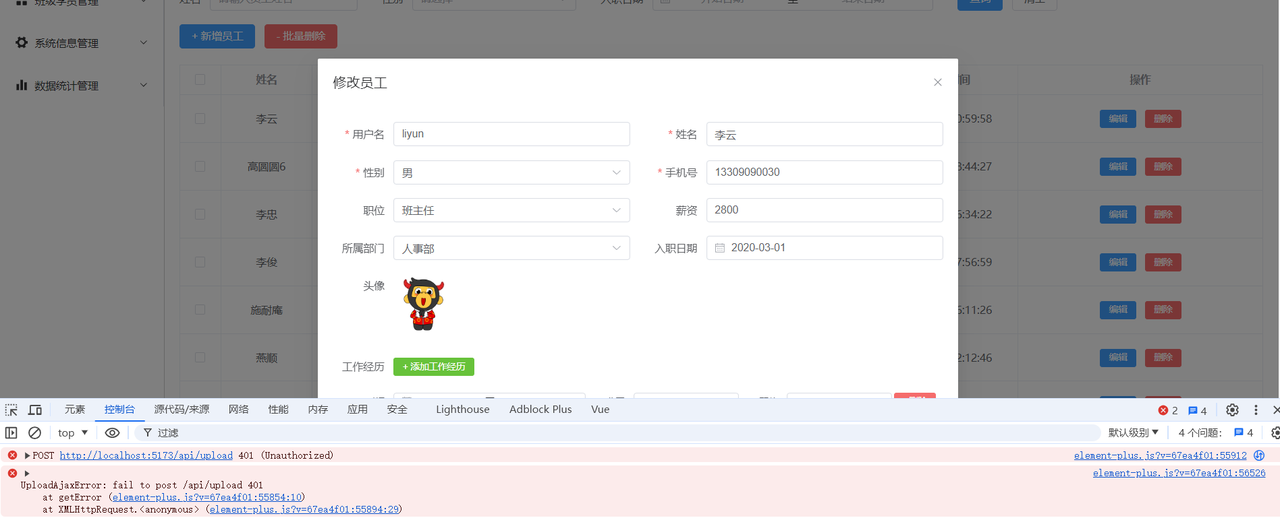

出现这个问题的原因是因为图片上传我们使用的是 ElementPlus 中提供的 el-upload 组件，请求服务端的时候并未通过axios，所以也并不会通过我们配置的axios的拦截器，携带请求头token 了。 服务器端，拦截到请求之后，发现未携带令牌，就会出现这个问题。

那接下来，针对于这个文件上传的请求，我们则需要单独处理一下。处理思路如下：

- 页面加载完毕后，从localStorage中获取登录员工信息，然后获取到token令牌。

- 然后在文件上传时，在请求头中将令牌携带到服务端。

具体操作步骤：

1). 在 src/views/emp/index.vue 中的 <script></script> 添加如下代码:

```javascript
//声明token
const token = ref('')

//钩子函数
onMounted(() => {
  search(); //查询员工列表数据
  queryAllDepts();//查询所有部门列表数据
  getToken(); //获取token
})

//获取token
const getToken = () => {
  const loginUser = JSON.parse(localStorage.getItem('loginUser'));
  if(loginUser && loginUser.token){
    token.value = loginUser.token;
  }
}
```

1). 在 src/views/emp/index.vue 中的 <template></template> 添加如下代码:

```html
<!-- 第五行 -->
        <el-row :gutter="20">
          <el-col :span="24">
            <el-form-item label="头像">
              <el-upload
                class="avatar-uploader"
                action="/api/upload"
                :headers="{'token': token}"
                :show-file-list="false"
                :on-success="handleAvatarSuccess"
                :before-upload="beforeAvatarUpload"
                >
                <img v-if="employee.image" :src="employee.image" class="avatar" />
                <el-icon v-else class="avatar-uploader-icon"><Plus /></el-icon>
              </el-upload>
            </el-form-item>
          </el-col>
        </el-row>
```

这样，这个问题就解决了，我们打开浏览器，测试一下文件上传。我们看到，在文件上传时，在请求头中携带了token令牌。

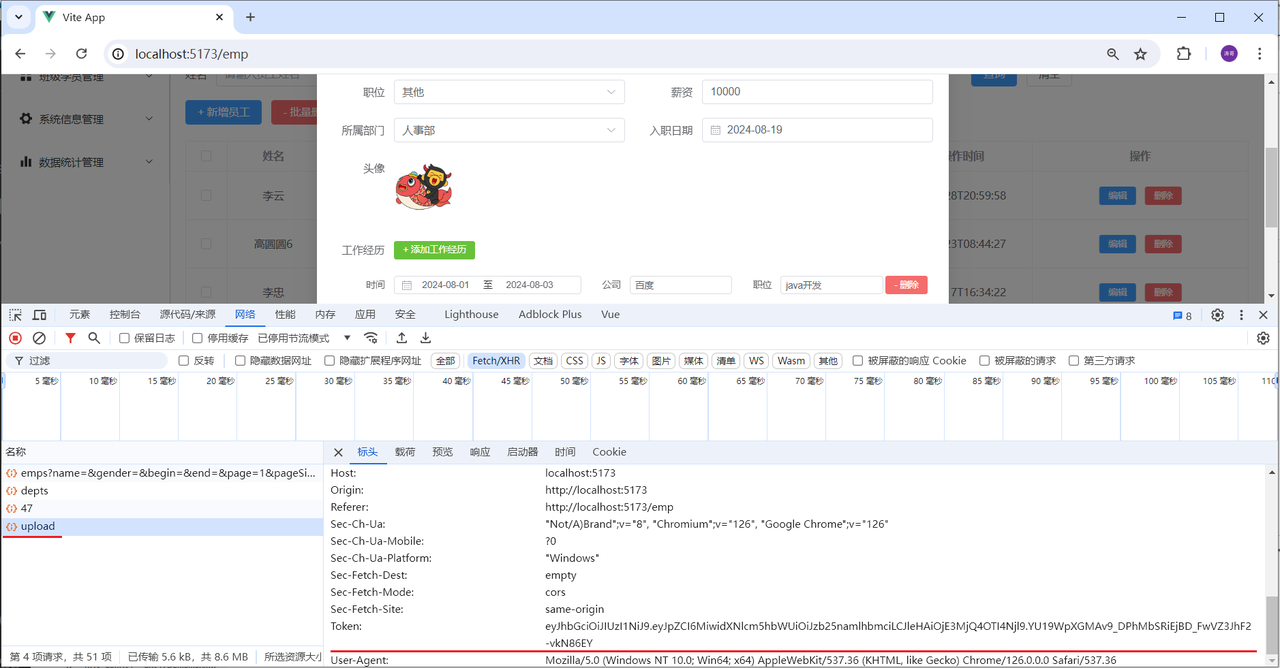

## 打包部署

> **补充｜配置分环境。** 开发环境和生产环境的 API 地址、代理路径和前端路由配置应分开管理。构建前检查环境变量，避免把本地接口地址写进生产包。

到此呢，部门管理、员工管理、登录认证的功能，我们都已经完成了。 那接下来，我们就来说一下前端工程的打包部署。 前端项目最终开发完毕之后，是需要打包，然后部署在nginx服务器上运行的 。

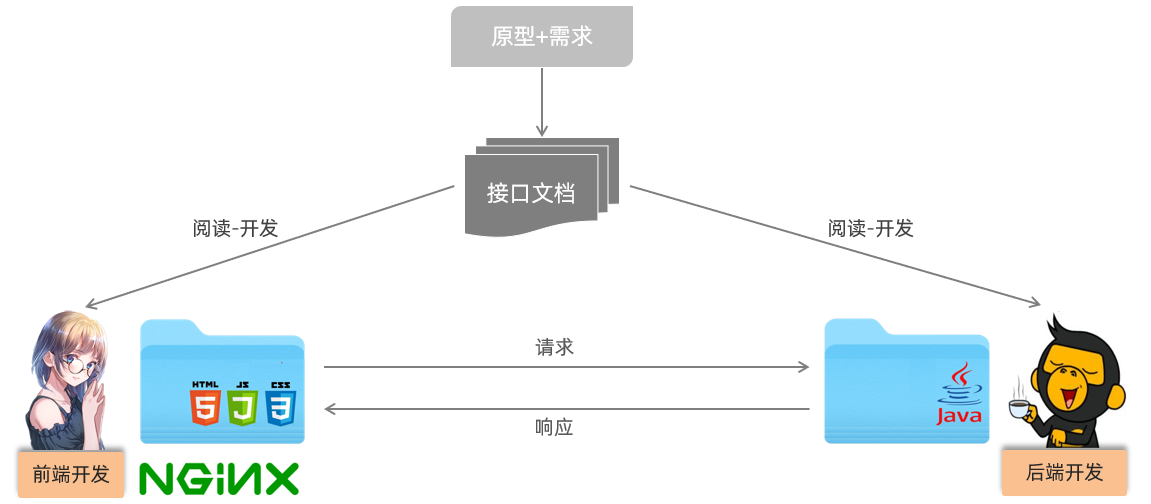

### 打包

> **补充｜构建产物检查。** 执行构建后检查 `dist` 中的入口 HTML、静态资源和资源路径，确认没有依赖开发服务器才能加载的文件。

直接双击npm脚本中的 build 即可将项目打包，打包后的文件会出现在 dist 目录中。

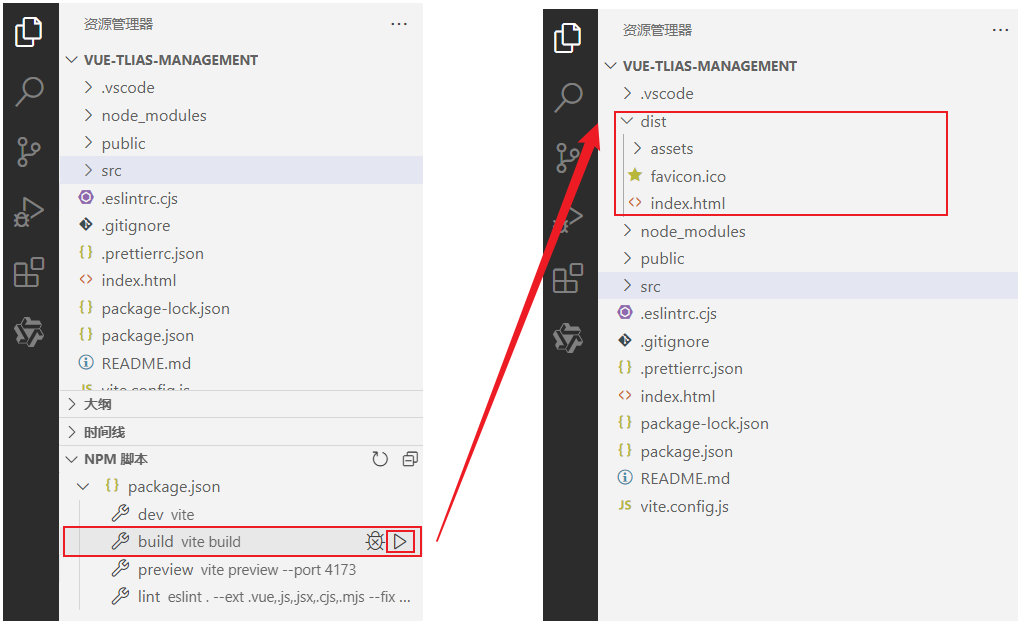

### 部署

> **补充｜Nginx 两类配置。** 静态资源由 `root` 托管，前端 history 路由需要 `try_files ... /index.html`；后端接口通过 `location /api` 反向代理到服务端，并正确转发请求头。

- Nginx

介绍：Nginx是一款轻量级的Web服务器/反向代理服务器及电子邮件（IMAP/POP3）代理服务器。其特点是占有内存少，并发能力强，在各大型互联网公司都有非常广泛的使用。

官网：https://nginx.org/

- 部署

打包完成之后，就可以将打包后的项目，部署到 nginx 服务器上了，记得将nginx解压到一个没有中文不带空格的目录中 。

然后直接将 dist 目录中的内容，拷贝到nginx的解压目录中的 html 中即可 (html目录下原有的两个文件, 可以直接删除)。

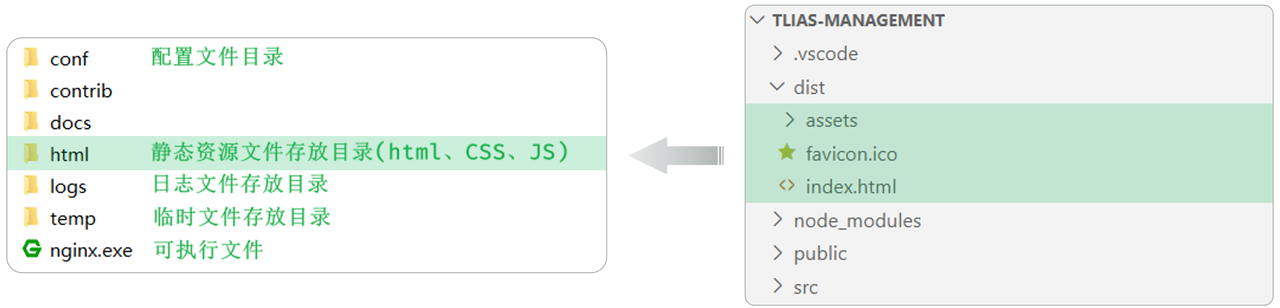

然后，在nginx服务器的核心配置文件 conf/nginx 中，在  http 配置块里面 添加如下反向代理的配置：

```json
server {
    listen       80;
    server_name  localhost;
    client_max_body_size 10m;

    location / {
        root   html;
        index  index.html index.htm;
        try_files $uri $uri/ /index.html;
    }
        
    location ^~ /api/ {
        rewrite ^/api/(.*)$ /$1 break;
        proxy_pass http://localhost:8080;
    }
        
    error_page   500 502 503 504  /50x.html;
    location = /50x.html {
        root   html;
    }
}
```

然后就可以双击 nginx.exe 启动项目了。 访问 http://localhost

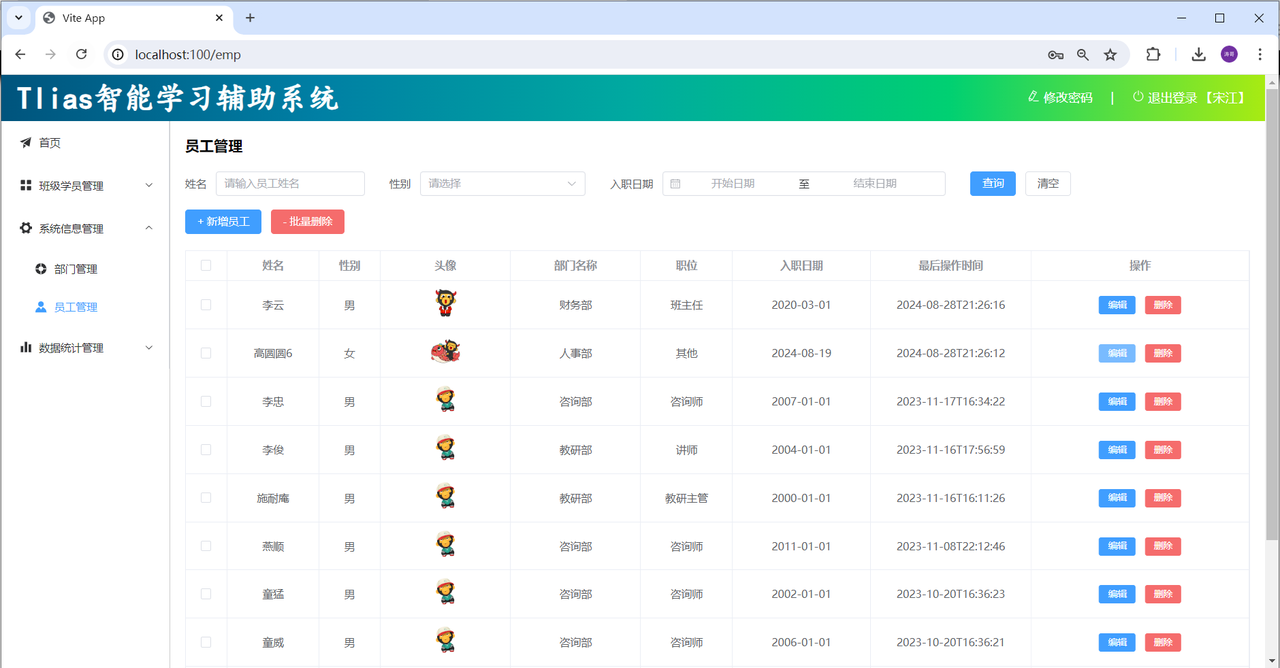

**讲义提示**

> Nginx默认占用80端口号，如果80端口号被占用，可以在nginx.conf中修改端口号。(netstat –ano | findStr  80)

Nginx服务器启动、重载、停止的相关命令：

- 启动：nginx.exe

- 重载：nginx.exe -s reload

- 停止：nginx.exe -s stop

## 复习速查与验收（补充）

| 知识点 | 记忆要点 | 常见误区 |
| --- | --- | --- |
| 修改回显 | 按 ID 查询详情，适配日期和嵌套表单数据 | 直接把列表行对象当完整详情使用 |
| 新增/修改复用 | 用是否存在 `id` 区分调用 `POST` 或 `PUT` | 修改后仍调用新增接口 |
| 单个删除 | 确认、请求、提示、刷新形成闭环 | 点击删除后直接改本地数组 |
| 批量删除 | selection-change 收集 ID，空选择不能提交 | 只保存整行对象，提交时字段不一致 |
| token | 登录后保存，拦截器统一携带 | 每个接口手动拼接且前缀不一致 |
| 401 处理 | 清理登录状态并跳转登录页 | 401 后继续重试造成跳转循环 |
| localStorage | 只保存必要的会话信息，读取时考虑空值 | 把密码或过多用户信息长期明文保存 |
| 文件上传 | upload 请求单独配置 headers | 误以为 Axios 拦截器自动作用于 `el-upload` |
| 打包部署 | 构建产物由 Nginx 托管，接口由反向代理转发 | 生产环境直接使用开发服务器 |

### 跟练验收

1. 点击编辑，员工基本信息、头像和工作经历均能正确回显，日期数组与接口字段对应。
2. 修改姓名或工作经历后保存，成功提示出现，弹窗关闭，列表显示新数据。
3. 单个删除取消确认时不发请求，确认后记录消失且总条数正确。
4. 选择多条员工执行批量删除，空选择不能提交，成功后选择状态清空。
5. 登录成功后 token 写入 `localStorage`，刷新页面仍能访问需要鉴权的接口。
6. 在 Network 面板确认业务请求带有正确的 `Authorization` 请求头。
7. 模拟或触发 401，确认 token 被清理并跳转登录页，不出现无限重定向。
8. 顶部显示当前登录用户，退出后回到登录页且旧用户信息不再展示。
9. 头像上传请求携带 token，文件类型和大小校验生效。
10. 执行生产构建并用 Nginx 托管 `dist`，刷新 history 路由和访问 `/api` 均正常。

### 自测问题

- 为什么编辑时需要重新查询详情，而不是只使用表格行对象？
- 如何用一个 Dialog 同时支持新增和修改？
- 批量删除时为什么要保存 ID 数组，并在成功后重新查询？
- Axios 请求拦截器和响应拦截器分别适合处理什么问题？
- `localStorage` 中保存 token 后，刷新页面如何恢复登录状态？
- `el-upload` 为什么可能没有自动携带 Axios 拦截器设置的 token？
- Nginx 部署 Vue history 路由时，`try_files` 解决什么问题？